     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.0/664.0 kB 21.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.7/6.7 MB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 237.1/237.1 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 53.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 MB 12.7 MB/s eta 0:00:00
Dependencies installed successfully.

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Qiskit: 1.4.6
Qiskit Aer: 0.17.1

HYBRID QUANTUM-CLASS

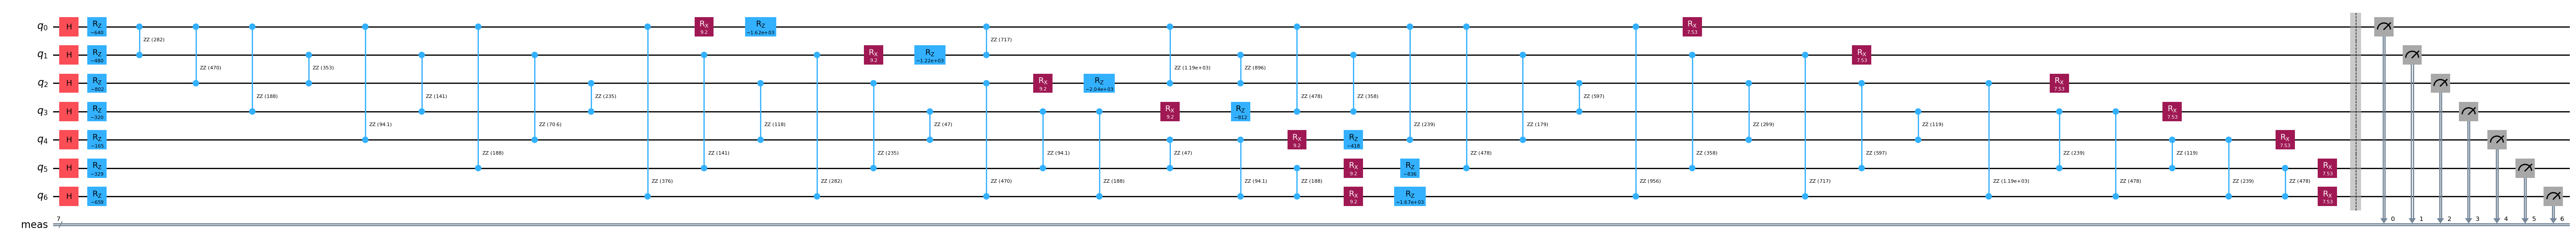


RUNNING QUANTUM SIMULATION
Shots: 4096

Top measurement results:
1100010 :  916 shots (22.36%)
1110100 :  700 shots (17.09%)
1100100 :  365 shots (8.91%)
1110010 :  279 shots (6.81%)
1101010 :  161 shots (3.93%)
1111100 :  144 shots (3.52%)
0100010 :  122 shots (2.98%)
0110100 :  120 shots (2.93%)
1110000 :  114 shots (2.78%)
1110110 :  100 shots (2.44%)
1000010 :   97 shots (2.37%)
1010100 :   73 shots (1.78%)
1101100 :   65 shots (1.59%)
0100100 :   64 shots (1.56%)
0110010 :   60 shots (1.46%)

DECODING QUANTUM RESULT

Best feasible QAOA solution:
Bitstring: 1100011
Probability: 0.29%
Cost: 7
Utility: 14

Selected tools:
  ✓ Web Search
  ✓ Database Search

CLASSICAL VS QUANTUM

Classical utility : 14
Quantum utility   : 14

Classical cost    : 7
Quantum cost      : 7

Utility recovered : 100.00%

Exact solution match: YES

QUANTUM MEASUREMENT DISTRIBUTION


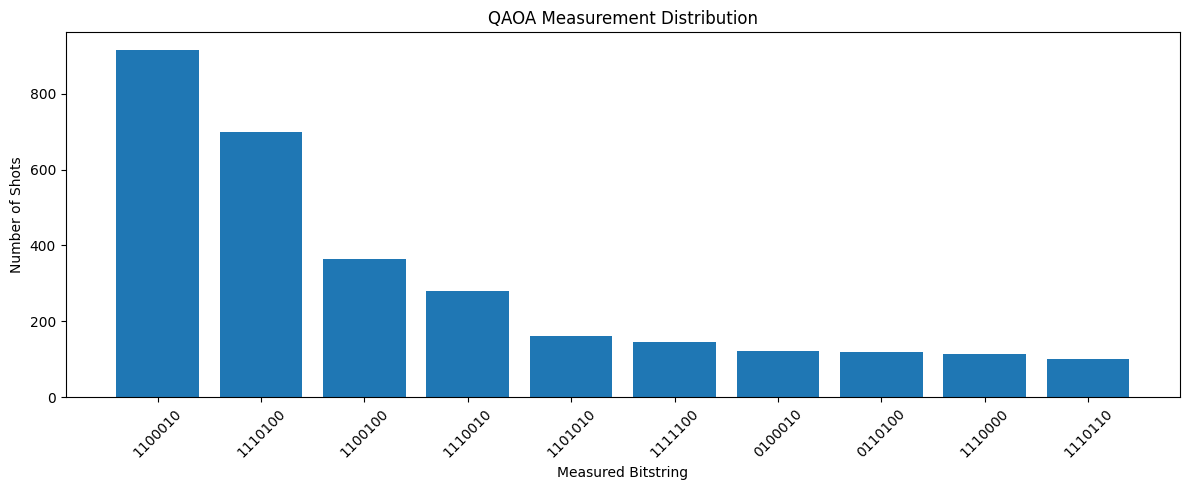

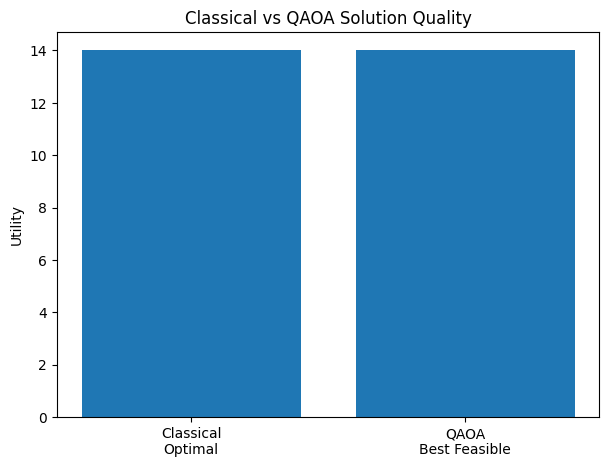

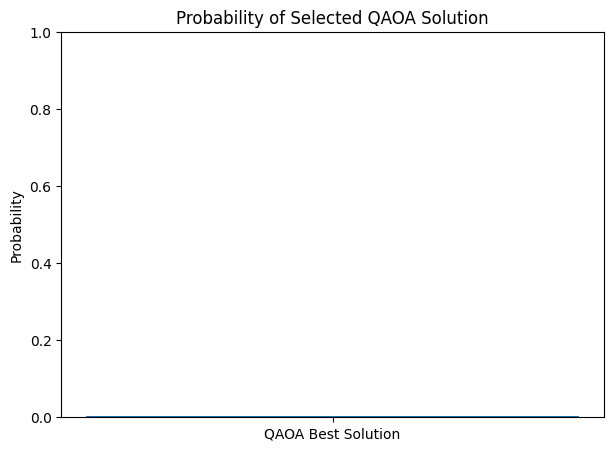



FINAL HYBRID AGENT REPORT

USER TASK
Select the most useful tools under a limited resource budget.

OPTIMIZATION
-------------------------------
Number of tools: 4
Quantum variables: 7
QAOA layers: 2
Shots: 4096

CLASSICAL BASELINE
-------------------------------
Selected:
  • Web Search
  • Database Search
Cost: 7
Utility: 14

QUANTUM QAOA
-------------------------------
Selected:
  • Web Search
  • Database Search
Cost: 7
Utility: 14

COMPARISON
-------------------------------
Utility recovery: 100.00%
Exact solution match: YES
Best-solution measurement probability: 0.29%

QUANTUM RESOURCES
-------------------------------
Qubits: 7
Circuit depth: 24
Total gates: 85



RESEARCH INTERPRETATION

The experiment demonstrates a hybrid architecture in which:

1. An agent understands the optimization task.
2. A classical control layer converts the task into a QUBO.
3. A classical exhaustive search provides a ground-truth baseline.
4. QAOA encodes the QUBO into a parameterized quantum circu

In [1]:
# ================================================================
# HYBRID QUANTUM-CLASSICAL LLM AGENT
# QAOA-BASED TOOL SELECTION OPTIMIZATION
#
# Complete Google Colab Demo
# ================================================================

# ================================================================
# 1. INSTALL DEPENDENCIES
# ================================================================

!pip install -q qiskit==1.4.6 qiskit-aer==0.17.1 \
    qiskit-optimization==0.7.0 qiskit-algorithms==0.4.0 \
    scipy matplotlib pylatexenc openai

print("Dependencies installed successfully.")


# ================================================================
# 2. IMPORTS
# ================================================================

import sys
import json
import math
import random
import itertools
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import minimize

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector

print("\nPython:", sys.version)
print("Qiskit:", __import__("qiskit").__version__)

try:
    import qiskit_aer
    print("Qiskit Aer:", qiskit_aer.__version__)
except:
    pass

print("\n================================================")
print("HYBRID QUANTUM-CLASSICAL LLM AGENT")
print("================================================")


# ================================================================
# 3. PROJECT ARCHITECTURE
# ================================================================

print("""
PROJECT ARCHITECTURE

                USER QUERY
                    |
                    v
          +-------------------+
          |  LLM / AGENT      |
          | Task Understanding|
          +-------------------+
                    |
                    v
          +-------------------+
          | Classical Control |
          |      Layer        |
          +-------------------+
                    |
                    v
             QUBO FORMULATION
                    |
          +---------+---------+
          |                   |
          v                   v
 +----------------+   +----------------+
 | Classical      |   | QAOA Quantum   |
 | Baseline       |   | Optimization   |
 +----------------+   +----------------+
          |                   |
          +---------+---------+
                    |
                    v
             RESULT COMPARISON
                    |
                    v
          +-------------------+
          | Agent Explanation |
          +-------------------+
                    |
                    v
              FINAL RESULT
""")


# ================================================================
# 4. OPTIONAL LLM AGENT
# ================================================================

# You can optionally enter an OpenAI API key.
# If you leave it empty, the notebook automatically uses
# the built-in demonstration configuration.

USE_LLM = False

# Example:
# USE_LLM = True
# from getpass import getpass
# OPENAI_API_KEY = getpass("Enter OpenAI API key: ")

OPENAI_API_KEY = ""


def llm_agent(user_query):
    """
    Optional LLM layer.

    The LLM converts a natural-language request into
    a structured optimization problem.

    If no API key is provided, a predefined configuration
    is returned so the complete quantum experiment still runs.
    """

    # ------------------------------------------------------------
    # Built-in demonstration configuration
    # ------------------------------------------------------------

    default_problem = {
        "task": "Select the most useful tools under a limited resource budget.",
        "budget": 7,
        "tools": [
            {
                "name": "Web Search",
                "cost": 4,
                "utility": 8
            },
            {
                "name": "Database Search",
                "cost": 3,
                "utility": 6
            },
            {
                "name": "Calculator",
                "cost": 5,
                "utility": 9
            },
            {
                "name": "Knowledge Retrieval",
                "cost": 2,
                "utility": 4
            }
        ]
    }

    if not USE_LLM or OPENAI_API_KEY == "":
        print("\n[Agent] Using built-in task configuration.")
        return default_problem

    try:
        from openai import OpenAI

        client = OpenAI(api_key=OPENAI_API_KEY)

        prompt = f"""
You are the planning component of a hybrid quantum-classical AI agent.

Convert the following user request into a small binary optimization
problem.

USER REQUEST:
{user_query}

Return ONLY valid JSON in this format:

{{
  "task": "short description",
  "budget": 7,
  "tools": [
    {{"name": "Tool A", "cost": 4, "utility": 8}},
    {{"name": "Tool B", "cost": 3, "utility": 6}},
    {{"name": "Tool C", "cost": 5, "utility": 9}},
    {{"name": "Tool D", "cost": 2, "utility": 4}}
  ]
}}

Use exactly four tools.
"""

        response = client.chat.completions.create(
            model="gpt-4o-mini",
            messages=[
                {
                    "role": "system",
                    "content": "You are an optimization problem parser."
                },
                {
                    "role": "user",
                    "content": prompt
                }
            ],
            temperature=0
        )

        content = response.choices[0].message.content
        return json.loads(content)

    except Exception as e:
        print("\nLLM unavailable. Falling back to built-in problem.")
        print("Reason:", str(e))

        return default_problem


# ================================================================
# 5. USER TASK
# ================================================================

user_query = """
An AI agent has several tools available.
It must select the combination of tools that provides
the highest utility while staying within a limited
computational/resource budget.
"""

problem = llm_agent(user_query)

print("\n================================================")
print("AGENT UNDERSTANDING")
print("================================================")

print("Task:")
print(problem["task"])

print("\nResource Budget:")
print(problem["budget"])

print("\nAvailable Tools:")

for tool in problem["tools"]:
    print(
        f"  {tool['name']:25s} "
        f"Cost={tool['cost']}  "
        f"Utility={tool['utility']}"
    )


# ================================================================
# 6. EXTRACT OPTIMIZATION DATA
# ================================================================

tools = problem["tools"]
budget = problem["budget"]

tool_names = [t["name"] for t in tools]
costs = [t["cost"] for t in tools]
utilities = [t["utility"] for t in tools]

n_tools = len(tools)

print("\nNumber of decision variables:", n_tools)


# ================================================================
# 7. CLASSICAL BASELINE
# ================================================================

print("\n================================================")
print("CLASSICAL BASELINE")
print("================================================")

best_solution = None
best_utility = -float("inf")
best_cost = None

classical_results = []

for selection in itertools.product([0, 1], repeat=n_tools):

    total_cost = sum(
        selection[i] * costs[i]
        for i in range(n_tools)
    )

    total_utility = sum(
        selection[i] * utilities[i]
        for i in range(n_tools)
    )

    feasible = total_cost <= budget

    if feasible:
        classical_results.append(
            (selection, total_cost, total_utility)
        )

        if total_utility > best_utility:
            best_utility = total_utility
            best_solution = selection
            best_cost = total_cost


print("\nClassical optimal solution:")

for i, selected in enumerate(best_solution):

    if selected == 1:
        print(
            f"  SELECTED: {tool_names[i]} "
            f"(cost={costs[i]}, utility={utilities[i]})"
        )

print("\nTotal Cost:", best_cost)
print("Total Utility:", best_utility)
print("Budget:", budget)


# ================================================================
# 8. BUILD QUBO
# ================================================================
#
# We need to transform:
#
#       maximize utility
#
# subject to:
#
#       total cost <= budget
#
# into an unconstrained binary optimization problem.
#
# We introduce slack variables:
#
#       cost + slack = budget
#
# Then use a penalty:
#
#       P(cost + slack - budget)^2
#
# ================================================================

print("\n================================================")
print("QUBO FORMULATION")
print("================================================")

P = 10.0

# Three slack bits can represent values from 0 to 7.
slack_weights = [1, 2, 4]

# Total variables:
# 4 tool variables + 3 slack variables
weights = costs + slack_weights

# Utility only belongs to tool variables.
qubo_utilities = utilities + [0, 0, 0]

n_qubits = len(weights)

print("Tool variables:", n_tools)
print("Slack variables:", len(slack_weights))
print("Total qubits:", n_qubits)
print("Penalty:", P)


# ------------------------------------------------
# QUBO:
#
# E(x) =
#
# - utility
# + P * (sum(weight*x) - budget)^2
#
# ------------------------------------------------

linear = []

for i in range(n_qubits):

    w = weights[i]
    u = qubo_utilities[i]

    coefficient = (
        -u
        + P * (w**2 - 2 * budget * w)
    )

    linear.append(coefficient)


quadratic = {}

for i in range(n_qubits):

    for j in range(i + 1, n_qubits):

        quadratic[(i, j)] = (
            2 * P * weights[i] * weights[j]
        )


constant = P * budget**2


def qubo_energy(bitstring):
    """
    Evaluate the QUBO energy for a binary solution.
    """

    x = [int(v) for v in bitstring]

    energy = constant

    for i in range(n_qubits):
        energy += linear[i] * x[i]

    for (i, j), coefficient in quadratic.items():
        energy += coefficient * x[i] * x[j]

    return energy


print("\nLinear coefficients:")
for i, value in enumerate(linear):
    print(f"  x{i}: {value:.2f}")


# ================================================================
# 9. VERIFY QUBO CLASSICALLY
# ================================================================

print("\n================================================")
print("QUBO VERIFICATION")
print("================================================")

qubo_solutions = []

for bits in itertools.product([0, 1], repeat=n_qubits):

    energy = qubo_energy(bits)

    original_cost = sum(
        bits[i] * weights[i]
        for i in range(n_qubits)
    )

    utility = sum(
        bits[i] * qubo_utilities[i]
        for i in range(n_qubits)
    )

    qubo_solutions.append(
        (
            energy,
            bits,
            original_cost,
            utility
        )
    )


qubo_solutions.sort(key=lambda x: x[0])

ground_energy, ground_bits, ground_cost, ground_utility = (
    qubo_solutions[0]
)

print("Lowest QUBO energy:", ground_energy)
print("QUBO bitstring:", "".join(map(str, ground_bits)))
print("Encoded cost:", ground_cost)
print("Encoded utility:", ground_utility)

print("\nThe QUBO ground state should correspond")
print("to the classical optimal tool selection.")


# ================================================================
# 10. QUBO -> ISING HAMILTONIAN
# ================================================================
#
# Binary variable:
#
#       x = (1 - Z) / 2
#
# Therefore:
#
#       QUBO -> Ising Hamiltonian
#
# The global constant can be ignored during QAOA
# because it does not change measurement probabilities.
# ================================================================

ising_linear = np.zeros(n_qubits)
ising_quadratic = {}

for i in range(n_qubits):

    coefficient = linear[i]

    # contribution from x_i
    ising_linear[i] += -coefficient / 2


for (i, j), coefficient in quadratic.items():

    # x_i*x_j =
    #
    # 1/4 (1 - Z_i - Z_j + Z_i Z_j)
    #

    ising_linear[i] += -coefficient / 4
    ising_linear[j] += -coefficient / 4

    ising_quadratic[(i, j)] = coefficient / 4


# ================================================================
# 11. QAOA CIRCUIT CONSTRUCTION
# ================================================================

def create_qaoa_circuit(gammas, betas, measure=False):

    p = len(gammas)

    qc = QuantumCircuit(n_qubits)

    # ------------------------------------------------------------
    # Initial |+> state
    # ------------------------------------------------------------

    for q in range(n_qubits):
        qc.h(q)

    # ------------------------------------------------------------
    # QAOA layers
    # ------------------------------------------------------------

    for layer in range(p):

        gamma = gammas[layer]
        beta = betas[layer]

        # -------------------------
        # Cost Hamiltonian
        # -------------------------

        for q in range(n_qubits):

            h = ising_linear[q]

            # RZ(theta) = exp(-i theta Z / 2)
            theta = 2 * gamma * h

            qc.rz(theta, q)

        for (i, j), J in ising_quadratic.items():

            theta = 2 * gamma * J

            qc.rzz(theta, i, j)

        # -------------------------
        # Mixer Hamiltonian
        # -------------------------

        for q in range(n_qubits):

            qc.rx(2 * beta, q)

    if measure:

        qc.measure_all()

    return qc


# ================================================================
# 12. QAOA EXPECTATION VALUE
# ================================================================

def qaoa_expectation(parameters, p=2):

    gammas = parameters[:p]
    betas = parameters[p:]

    qc = create_qaoa_circuit(
        gammas,
        betas,
        measure=False
    )

    state = Statevector.from_instruction(qc)

    probabilities = np.abs(state.data) ** 2

    expectation = 0.0

    # Qiskit basis-state indexing:
    # integer index corresponds to computational basis.
    #
    # Convert integer to bit vector.
    # ------------------------------------------------------------

    for index, probability in enumerate(probabilities):

        if probability < 1e-12:
            continue

        bitstring = format(
            index,
            f"0{n_qubits}b"
        )

        # Qiskit ordering is reversed relative to
        # our conceptual variable ordering.
        bits = tuple(
            int(bitstring[-1 - q])
            for q in range(n_qubits)
        )

        energy = qubo_energy(bits)

        expectation += probability * energy

    return float(expectation)


# ================================================================
# 13. OPTIMIZE QAOA PARAMETERS
# ================================================================

print("\n================================================")
print("QAOA PARAMETER OPTIMIZATION")
print("================================================")

P_LAYERS = 2

random.seed(42)
np.random.seed(42)

best_qaoa_result = None

number_of_restarts = 5

for restart in range(number_of_restarts):

    initial_parameters = np.random.uniform(
        0,
        2 * np.pi,
        2 * P_LAYERS
    )

    result = minimize(
        qaoa_expectation,
        initial_parameters,
        args=(P_LAYERS,),
        method="COBYLA",
        options={
            "maxiter": 150,
            "tol": 1e-4
        }
    )

    print(
        f"Restart {restart + 1}: "
        f"Expectation = {result.fun:.4f}"
    )

    if (
        best_qaoa_result is None
        or result.fun < best_qaoa_result.fun
    ):
        best_qaoa_result = result


optimal_parameters = best_qaoa_result.x

optimal_gammas = optimal_parameters[:P_LAYERS]
optimal_betas = optimal_parameters[P_LAYERS:]

print("\nBest QAOA expectation:")
print(best_qaoa_result.fun)

print("\nOptimal gamma parameters:")
print(optimal_gammas)

print("\nOptimal beta parameters:")
print(optimal_betas)


# ================================================================
# 14. DISPLAY QAOA CIRCUIT
# ================================================================

print("\n================================================")
print("QAOA QUANTUM CIRCUIT")
print("================================================")

qaoa_circuit = create_qaoa_circuit(
    optimal_gammas,
    optimal_betas,
    measure=True
)

print(qaoa_circuit)

print("\nCircuit depth:", qaoa_circuit.depth())
print("Number of qubits:", qaoa_circuit.num_qubits)
print("Number of gates:", len(qaoa_circuit.data))


# ================================================================
# 15. CIRCUIT VISUALIZATION
# ================================================================

try:

    display(
        qaoa_circuit.draw(
            "mpl",
            fold=100
        )
    )

except Exception:

    print(qaoa_circuit.draw())


# ================================================================
# 16. RUN QAOA USING QISKIT AER
# ================================================================

print("\n================================================")
print("RUNNING QUANTUM SIMULATION")
print("================================================")

simulator = AerSimulator()

transpiled_qc = transpile(
    qaoa_circuit,
    simulator
)

shots = 4096

job = simulator.run(
    transpiled_qc,
    shots=shots
)

result = job.result()

counts = result.get_counts()

print("Shots:", shots)

print("\nTop measurement results:")

sorted_counts = sorted(
    counts.items(),
    key=lambda x: x[1],
    reverse=True
)

for bitstring, count in sorted_counts[:15]:

    probability = count / shots

    print(
        f"{bitstring} : "
        f"{count:4d} shots "
        f"({probability:.2%})"
    )


# ================================================================
# 17. DECODE QUANTUM RESULTS
# ================================================================

print("\n================================================")
print("DECODING QUANTUM RESULT")
print("================================================")


def qiskit_to_variable_bits(bitstring):

    # Reverse Qiskit's display order.
    return tuple(
        int(bitstring[-1 - q])
        for q in range(n_qubits)
    )


quantum_candidates = []

for bitstring, count in counts.items():

    bits = qiskit_to_variable_bits(bitstring)

    # First four bits correspond to tools.
    selected_tools = bits[:n_tools]

    total_cost = sum(
        selected_tools[i] * costs[i]
        for i in range(n_tools)
    )

    total_utility = sum(
        selected_tools[i] * utilities[i]
        for i in range(n_tools)
    )

    probability = count / shots

    feasible = total_cost <= budget

    quantum_candidates.append(
        {
            "bitstring": bitstring,
            "bits": bits,
            "count": count,
            "probability": probability,
            "cost": total_cost,
            "utility": total_utility,
            "feasible": feasible
        }
    )


# Sort by:
# 1. feasibility
# 2. utility
# 3. probability

feasible_candidates = [
    x for x in quantum_candidates
    if x["feasible"]
]

if len(feasible_candidates) > 0:

    feasible_candidates.sort(
        key=lambda x: (
            x["utility"],
            x["probability"]
        ),
        reverse=True
    )

    quantum_best = feasible_candidates[0]

else:

    quantum_candidates.sort(
        key=lambda x: x["probability"],
        reverse=True
    )

    quantum_best = quantum_candidates[0]


print("\nBest feasible QAOA solution:")

print(
    "Bitstring:",
    quantum_best["bitstring"]
)

print(
    "Probability:",
    f"{quantum_best['probability']:.2%}"
)

print(
    "Cost:",
    quantum_best["cost"]
)

print(
    "Utility:",
    quantum_best["utility"]
)

print("\nSelected tools:")

for i, selected in enumerate(
    quantum_best["bits"][:n_tools]
):

    if selected:

        print(
            f"  ✓ {tool_names[i]}"
        )


# ================================================================
# 18. CLASSICAL VS QUANTUM COMPARISON
# ================================================================

print("\n================================================")
print("CLASSICAL VS QUANTUM")
print("================================================")

classical_utility = best_utility
quantum_utility = quantum_best["utility"]

classical_cost = best_cost
quantum_cost = quantum_best["cost"]

if classical_utility != 0:

    utility_match = (
        quantum_utility / classical_utility
    ) * 100

else:

    utility_match = 0


same_solution = (
    quantum_utility == classical_utility
    and quantum_cost == classical_cost
)


print(
    f"\nClassical utility : {classical_utility}"
)

print(
    f"Quantum utility   : {quantum_utility}"
)

print(
    f"\nClassical cost    : {classical_cost}"
)

print(
    f"Quantum cost      : {quantum_cost}"
)

print(
    f"\nUtility recovered : {utility_match:.2f}%"
)

print(
    "\nExact solution match:",
    "YES" if same_solution else "NO"
)


# ================================================================
# 19. MEASUREMENT RESULT VISUALIZATION
# ================================================================

print("\n================================================")
print("QUANTUM MEASUREMENT DISTRIBUTION")
print("================================================")

top_results = sorted_counts[:10]

labels = [
    x[0]
    for x in top_results
]

values = [
    x[1]
    for x in top_results
]

plt.figure(figsize=(12, 5))

plt.bar(
    labels,
    values
)

plt.xlabel("Measured Bitstring")
plt.ylabel("Number of Shots")
plt.title(
    "QAOA Measurement Distribution"
)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


# ================================================================
# 20. CLASSICAL VS QUANTUM UTILITY GRAPH
# ================================================================

plt.figure(figsize=(7, 5))

plt.bar(
    ["Classical\nOptimal", "QAOA\nBest Feasible"],
    [
        classical_utility,
        quantum_utility
    ]
)

plt.ylabel("Utility")

plt.title(
    "Classical vs QAOA Solution Quality"
)

plt.show()


# ================================================================
# 21. SOLUTION PROBABILITY
# ================================================================

plt.figure(figsize=(7, 5))

plt.bar(
    ["QAOA Best Solution"],
    [quantum_best["probability"]]
)

plt.ylabel("Probability")

plt.title(
    "Probability of Selected QAOA Solution"
)

plt.ylim(0, 1)

plt.show()


# ================================================================
# 22. FINAL AGENT REPORT
# ================================================================

print("\n")
print("=" * 65)
print("FINAL HYBRID AGENT REPORT")
print("=" * 65)

print("\nUSER TASK")
print(problem["task"])

print("\nOPTIMIZATION")
print("-------------------------------")
print("Number of tools:", n_tools)
print("Quantum variables:", n_qubits)
print("QAOA layers:", P_LAYERS)
print("Shots:", shots)

print("\nCLASSICAL BASELINE")
print("-------------------------------")

print("Selected:")

for i, selected in enumerate(best_solution):

    if selected:

        print(
            f"  • {tool_names[i]}"
        )

print("Cost:", classical_cost)
print("Utility:", classical_utility)

print("\nQUANTUM QAOA")
print("-------------------------------")

print("Selected:")

for i, selected in enumerate(
    quantum_best["bits"][:n_tools]
):

    if selected:

        print(
            f"  • {tool_names[i]}"
        )

print("Cost:", quantum_cost)
print("Utility:", quantum_utility)

print("\nCOMPARISON")
print("-------------------------------")

print(
    "Utility recovery:",
    f"{utility_match:.2f}%"
)

print(
    "Exact solution match:",
    "YES" if same_solution else "NO"
)

print(
    "Best-solution measurement probability:",
    f"{quantum_best['probability']:.2%}"
)

print("\nQUANTUM RESOURCES")
print("-------------------------------")

print("Qubits:", qaoa_circuit.num_qubits)
print("Circuit depth:", qaoa_circuit.depth())
print("Total gates:", len(qaoa_circuit.data))

print("\n")
print("=" * 65)

print("""
RESEARCH INTERPRETATION

The experiment demonstrates a hybrid architecture in which:

1. An agent understands the optimization task.
2. A classical control layer converts the task into a QUBO.
3. A classical exhaustive search provides a ground-truth baseline.
4. QAOA encodes the QUBO into a parameterized quantum circuit.
5. A classical optimizer tunes the QAOA parameters.
6. Qiskit Aer simulates the quantum circuit.
7. Measurement results are decoded into a tool-selection decision.
8. The quantum solution is compared with the classical solution.

This experiment does NOT assume quantum advantage.

For small problem sizes, classical methods may be faster.
The purpose is to evaluate the integration of a quantum
optimization component into an AI-agent architecture and
measure solution quality and quantum resource requirements.
""")

HYBRID_QUANTUM_CLASSICAL_LLM_AGENT_PROJECT

In [2]:
!pip install qiskit qiskit-aer qiskit-optimization pennylane transformers torch networkx matplotlib -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 80.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 53.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 40.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 98.1 MB/s eta 0:00:00


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import time

# Classical LLM
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

# Quantum - Qiskit (Grover + QAOA)
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.circuit.library import GroverOperator, MCMTGate, ZGate
from qiskit.quantum_info import Statevector
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.algorithms import MinimumEigenOptimizer
from qiskit_algorithms import QAOA, NumPyMinimumEigensolver
from qiskit_algorithms.optimizers import COBYLA
from qiskit.primitives import Sampler

# Quantum - PennyLane (Variational circuit for embeddings)
import pennylane as qml

In [4]:
class ClassicalAgent:
    """
    The LLM acts as the classical orchestrator: given a task description,
    it proposes a set of candidate actions/tools in natural language.
    We use a small causal LM here so this runs on Colab's free tier.
    """
    def __init__(self, model_name="distilgpt2"):
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        self.model = AutoModelForCausalLM.from_pretrained(model_name)
        self.model.eval()

    def propose_actions(self, task_prompt, n_candidates=8, max_new_tokens=12):
        candidates = []
        inputs = self.tokenizer(task_prompt, return_tensors="pt")
        for _ in range(n_candidates):
            with torch.no_grad():
                out = self.model.generate(
                    **inputs,
                    max_new_tokens=max_new_tokens,
                    do_sample=True,
                    top_k=50,
                    temperature=0.9,
                    pad_token_id=self.tokenizer.eos_token_id,
                )
            text = self.tokenizer.decode(out[0], skip_special_tokens=True)
            candidates.append(text[len(task_prompt):].strip())
        return candidates

agent = ClassicalAgent()
task_prompt = "To finish the report, the agent should"
candidate_actions = agent.propose_actions(task_prompt, n_candidates=8)
for i, c in enumerate(candidate_actions):
    print(f"[{i}] {c}")

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

[0] be happy to put the new report's contents directly to the
[1] now be able to update the project automatically, so that it
[2] use the following instructions:
[3] also start to check the reports and that he has obtained a
[4] confirm that she has not reached the end of the article and
[5] be contacted by the agent, and then asked for an explanation
[6] also remove the device card from the device and add the device
[7] be able to verify the identity of the individual who died.


In [5]:
def score_action(text):
    """
    Toy scoring heuristic standing in for a reward model:
    rewards actions containing task-relevant keywords.
    Replace with a real reward/classifier for production use.
    """
    keywords = ["search", "write", "read", "check", "send", "save", "review"]
    return sum(kw in text.lower() for kw in keywords)

def grover_select_action(candidates, scores):
    """
    Encodes candidate indices as computational basis states and uses
    Grover's algorithm to amplify the amplitude of the best-scoring one(s).
    """
    n = int(np.ceil(np.log2(len(candidates))))
    n = max(n, 1)
    N = 2 ** n

    padded_scores = scores + [-1] * (N - len(scores))
    best_score = max(padded_scores)
    marked = [i for i, s in enumerate(padded_scores) if s == best_score]

    # Build oracle: phase-flip marked basis states
    oracle = QuantumCircuit(n)
    for m in marked:
        bits = format(m, f"0{n}b")
        for i, b in enumerate(reversed(bits)):
            if b == "0":
                oracle.x(i)
        if n == 1:
            oracle.z(0)
        else:
            oracle.append(MCMTGate(ZGate(), n - 1, 1), list(range(n)))
        for i, b in enumerate(reversed(bits)):
            if b == "0":
                oracle.x(i)

    grover_op = GroverOperator(oracle)
    iterations = max(1, int(np.floor(np.pi / 4 * np.sqrt(N / len(marked)))))

    qc = QuantumCircuit(n, n)
    qc.h(range(n))
    for _ in range(iterations):
        qc.compose(grover_op, inplace=True)
    qc.measure(range(n), range(n))

    sim = AerSimulator()
    result = sim.run(transpile(qc, sim), shots=512).result()
    counts = result.get_counts()
    best_bit = max(counts, key=counts.get)
    idx = int(best_bit, 2)
    idx = min(idx, len(candidates) - 1)
    return idx, counts

scores = [score_action(c) for c in candidate_actions]
selected_idx, counts = grover_select_action(candidate_actions, scores)
print("Selected action:", candidate_actions[selected_idx])
print("Measurement distribution:", counts)

Selected action: also start to check the reports and that he has obtained a
Measurement distribution: {'110': 2, '001': 3, '100': 4, '000': 5, '010': 6, '111': 5, '011': 487}


In [6]:
from qiskit.primitives import StatevectorSampler

def build_planning_qubo(task_nodes, edges_with_cost):
    """
    Models step-ordering / scheduling as a small QUBO:
    minimize total transition cost while visiting each task node once
    (simplified TSP-style formulation for a handful of subtasks).
    """
    qp = QuadraticProgram("plan_optimization")
    for node in task_nodes:
        qp.binary_var(name=node)

    linear = {node: 0 for node in task_nodes}
    quadratic = {}
    for (a, b), cost in edges_with_cost.items():
        quadratic[(a, b)] = quadratic.get((a, b), 0) + cost

    qp.minimize(linear=linear, quadratic=quadratic)
    return qp

task_nodes = ["gather_data", "analyze", "draft", "review"]
edges_with_cost = {
    ("gather_data", "analyze"): -2,
    ("analyze", "draft"): -3,
    ("draft", "review"): -2,
    ("gather_data", "review"): 1,
}

qp = build_planning_qubo(task_nodes, edges_with_cost)

sampler = StatevectorSampler()   # V2 primitive
qaoa = QAOA(sampler=sampler, optimizer=COBYLA(maxiter=100), reps=2)
qaoa_optimizer = MinimumEigenOptimizer(qaoa)

result = qaoa_optimizer.solve(qp)
print("Optimized plan selection (1 = include/prioritize step):")
for var, val in zip(task_nodes, result.x):
    print(f"  {var}: {int(val)}")
print("Objective value:", result.fval)

Optimized plan selection (1 = include/prioritize step):
  gather_data: 1
  analyze: 1
  draft: 1
  review: 1
Objective value: -6.0


In [7]:
n_qubits = 4
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev)
def embedding_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(n_qubits))
    qml.BasicEntanglerLayers(weights, wires=range(n_qubits))
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

def compress_embedding(classical_vector, weights):
    """
    Compresses a classical embedding vector into a low-dimensional
    quantum-derived feature vector for cheaper similarity search.
    """
    vec = np.array(classical_vector[:n_qubits])
    if len(vec) < n_qubits:
        vec = np.pad(vec, (0, n_qubits - len(vec)))
    vec = np.pi * (vec - vec.min()) / (vec.max() - vec.min() + 1e-9)
    return np.array(embedding_circuit(vec, weights))

np.random.seed(0)
weights = np.random.uniform(0, np.pi, (2, n_qubits))

doc_embeddings = {
    "doc_A": np.random.rand(8),
    "doc_B": np.random.rand(8),
    "doc_C": np.random.rand(8),
}

compressed = {name: compress_embedding(vec, weights) for name, vec in doc_embeddings.items()}

def cosine_sim(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9)

query = compress_embedding(np.random.rand(8), weights)
similarities = {name: cosine_sim(query, emb) for name, emb in compressed.items()}
print("Retrieval similarities (quantum-compressed space):", similarities)
best_match = max(similarities, key=similarities.get)
print("Best matching document:", best_match)

Retrieval similarities (quantum-compressed space): {'doc_A': np.float64(-0.10490313484559463), 'doc_B': np.float64(0.7958081838518135), 'doc_C': np.float64(0.15269856831078943)}
Best matching document: doc_B


In [8]:
class QuantumControlLayer:
    """
    Mediates data flow between the classical LLM agent and the
    quantum co-processor: encoding classical data into circuits,
    dispatching to simulator/backend, decoding measurements back
    into the agent's action/token space.
    """
    def __init__(self, backend=None):
        self.backend = backend or AerSimulator()

    def encode_choice_space(self, n_options):
        return int(np.ceil(np.log2(max(n_options, 2))))

    def decode_measurement(self, counts, candidates):
        best_bit = max(counts, key=counts.get)
        idx = min(int(best_bit, 2), len(candidates) - 1)
        confidence = counts[best_bit] / sum(counts.values())
        return candidates[idx], confidence

control = QuantumControlLayer()
chosen_action, confidence = control.decode_measurement(counts, candidate_actions)
print(f"Control layer decoded action: '{chosen_action}' (confidence={confidence:.2f})")

Control layer decoded action: 'also start to check the reports and that he has obtained a' (confidence=0.95)


In [9]:
def hybrid_agent_step(task_prompt, agent, weights):
    t0 = time.time()

    # 1. Classical LLM proposes candidate actions
    candidates = agent.propose_actions(task_prompt, n_candidates=8)
    scores = [score_action(c) for c in candidates]

    # 2. Quantum Grover search picks the best action
    idx, counts = grover_select_action(candidates, scores)
    chosen_action, confidence = control.decode_measurement(counts, candidates)

    # 3. QAOA optimizes the surrounding multi-step plan
    plan_result = qaoa_optimizer.solve(qp)

    # 4. Variational circuit ranks relevant retrieved context
    query_vec = compress_embedding(np.random.rand(8), weights)
    sims = {name: cosine_sim(query_vec, emb) for name, emb in compressed.items()}
    best_doc = max(sims, key=sims.get)

    t1 = time.time()
    return {
        "chosen_action": chosen_action,
        "confidence": confidence,
        "plan_objective": plan_result.fval,
        "retrieved_doc": best_doc,
        "latency_sec": t1 - t0,
    }

output = hybrid_agent_step(task_prompt, agent, weights)
print(output)

{'chosen_action': 'receive a second call from the FBI, if the matter is', 'confidence': 0.140625, 'plan_objective': np.float64(-6.0), 'retrieved_doc': 'doc_A', 'latency_sec': 7.383947134017944}


In [10]:
def classical_agent_step(task_prompt, agent):
    t0 = time.time()
    candidates = agent.propose_actions(task_prompt, n_candidates=8)
    scores = [score_action(c) for c in candidates]
    best_idx = int(np.argmax(scores))  # brute-force argmax, no quantum search

    # classical greedy plan ordering
    order = sorted(task_nodes, key=lambda n: sum(
        c for (a, b), c in edges_with_cost.items() if a == n or b == n))

    query = np.random.rand(8)
    sims = {name: cosine_sim(query, vec) for name, vec in doc_embeddings.items()}
    best_doc = max(sims, key=sims.get)

    t1 = time.time()
    return {
        "chosen_action": candidates[best_idx],
        "plan_order": order,
        "retrieved_doc": best_doc,
        "latency_sec": t1 - t0,
    }

classical_output = classical_agent_step(task_prompt, agent)
print(classical_output)

{'chosen_action': 'send it directly to the FBI.', 'plan_order': ['analyze', 'draft', 'gather_data', 'review'], 'retrieved_doc': 'doc_B', 'latency_sec': 4.833984613418579}


In [11]:
n_trials = 10
hybrid_latencies, classical_latencies = [], []

for _ in range(n_trials):
    hybrid_latencies.append(hybrid_agent_step(task_prompt, agent, weights)["latency_sec"])
    classical_latencies.append(classical_agent_step(task_prompt, agent)["latency_sec"])

plt.figure(figsize=(7, 4))
plt.plot(hybrid_latencies, marker="o", label="Hybrid quantum-classical")
plt.plot(classical_latencies, marker="s", label="Classical-only baseline")
plt.xlabel("Trial")
plt.ylabel("Latency (s)")
plt.title("Agent Decision Latency: Hybrid vs Classical")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Mean hybrid latency:    {np.mean(hybrid_latencies):.3f}s")
print(f"Mean classical latency: {np.mean(classical_latencies):.3f}s")

KeyboardInterrupt: 

HYBRID_QUANTUM_CLASSICAL_LLM_AGENTT_2(TEST)

In [12]:
# ============================================================
# BLOCK 1 — INSTALL PROJECT DEPENDENCIES
# ============================================================

!pip install -q \
    qiskit==1.4.6 \
    qiskit-aer==0.17.1 \
    qiskit-optimization==0.7.0 \
    qiskit-algorithms==0.4.0 \
    qiskit-ibm-runtime \
    transformers \
    accelerate \
    sentencepiece \
    scipy \
    matplotlib \
    pandas \
    pylatexenc

print("All project dependencies installed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 32.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 37.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.6/76.6 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.3/130.3 kB 13.5 MB/s eta 0:00:00
All project dependencies installed.


In [13]:
# ============================================================
# BLOCK 2 — ENVIRONMENT CHECK
# ============================================================

import sys
import qiskit
import qiskit_aer
import qiskit_optimization
import qiskit_algorithms

print("Python:", sys.version)
print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)
print("Qiskit Optimization:", qiskit_optimization.__version__)
print("Qiskit Algorithms:", qiskit_algorithms.__version__)

try:
    import qiskit_ibm_runtime
    print("IBM Runtime:", qiskit_ibm_runtime.__version__)
except Exception as e:
    print("IBM Runtime import error:", e)

try:
    import transformers
    print("Transformers:", transformers.__version__)
except Exception as e:
    print("Transformers error:", e)

import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

print("\nEnvironment check complete.")

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Qiskit: 1.4.6
Qiskit Aer: 0.17.1
Qiskit Optimization: 0.7.0
Qiskit Algorithms: 0.4.0
IBM Runtime: 0.44.1
Transformers: 5.18.0
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4

Environment check complete.


In [14]:
# ============================================================
# BLOCK 3 — PROJECT IMPORTS
# ============================================================

import json
import re
import time
import itertools
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

from qiskit.quantum_info import Statevector

from qiskit.circuit import Parameter

from scipy.optimize import minimize

print("Imports successful.")

Imports successful.


In [15]:
# ============================================================
# BLOCK 4 — LOCAL QWEN LLM
# ============================================================

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

print("Loading:", MODEL_NAME)
print("This may take a little while the first time...\n")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype="auto",
    device_map="auto"
)

model.eval()

print("Qwen model loaded successfully.")
print("Device:", model.device)

Loading: Qwen/Qwen2.5-0.5B-Instruct
This may take a little while the first time...



config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen model loaded successfully.
Device: cuda:0


In [16]:
# ============================================================
# BLOCK 5 — TEST LOCAL QWEN LLM
# ============================================================

def ask_qwen(prompt, max_new_tokens=250):

    messages = [
        {
            "role": "system",
            "content": """
You are the classical orchestration component of a
hybrid quantum-classical AI agent.

Your job is to understand a user's task and propose
candidate actions, subgoals, constraints, and optimization
objectives.

Be concise and structured.
"""
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    # Convert chat messages into a normal text prompt
    formatted_prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    # Tokenize the text normally
    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt",
        padding=True
    )

    # Move tensors to the T4 GPU
    inputs = {
        key: value.to(model.device)
        for key, value in inputs.items()
    }

    # Generate response
    with torch.no_grad():

        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    # Get only the newly generated tokens
    input_length = inputs["input_ids"].shape[1]

    generated_tokens = outputs[0, input_length:]

    response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return response


# ============================================================
# TEST QUERY
# ============================================================

test_query = """
I need an AI agent to plan a trip from Hyderabad to Bangalore.

It can use:
1. train search
2. bus search
3. flight search
4. hotel search

The agent should minimize cost while satisfying the
travel requirements.

What candidate actions and subgoals should the agent consider?
"""


print("================================================")
print("USER QUERY")
print("================================================")

print(test_query)


print("\n================================================")
print("QWEN RESPONSE")
print("================================================")

start_time = time.perf_counter()

response = ask_qwen(
    test_query,
    max_new_tokens=250
)

llm_time = time.perf_counter() - start_time

print(response)


print("\n================================================")
print("LLM INFORMATION")
print("================================================")

print("Model:", MODEL_NAME)
print("Device:", model.device)
print("Execution time:", f"{llm_time:.2f} seconds")

USER QUERY

I need an AI agent to plan a trip from Hyderabad to Bangalore.

It can use:
1. train search
2. bus search
3. flight search
4. hotel search

The agent should minimize cost while satisfying the
travel requirements.

What candidate actions and subgoals should the agent consider?


QWEN RESPONSE
To plan a trip from Hyderabad to Bangalore using the provided options, the agent should consider the following:

### Candidate Actions:
1. **Train Search**
   - Identify trains that connect Hyderabad to Bangalore.
   
2. **Bus Search**
   - Find buses that run between Hyderabad and Bangalore.
   
3. **Flight Search**
   - Look for flights connecting Hyderabad to Bangalore.
   
4. **Hotel Search**
   - Determine if there are hotels in or near Bangalore where the traveler can stay during their journey.

### Subgoals:
- **Cost Minimization**: Ensure that the total travel cost (including airfare, transportation costs, accommodation) is minimized.
- **Travel Requirements**: Verify that the p

In [17]:
# ============================================================
# BLOCK 6 — LLM → STRUCTURED AGENT ACTIONS
# ============================================================

def extract_agent_actions(llm_response):
    """
    Convert the LLM's natural-language response into
    structured candidate actions and subgoals.
    """

    actions = []
    subgoals = []

    # --------------------------------------------------------
    # Candidate actions
    # --------------------------------------------------------

    action_keywords = {
        "train search": "train_search",
        "bus search": "bus_search",
        "flight search": "flight_search",
        "hotel search": "hotel_search"
    }

    response_lower = llm_response.lower()

    for keyword, action_name in action_keywords.items():

        if keyword in response_lower:
            actions.append(action_name)

    # --------------------------------------------------------
    # Subgoals
    # --------------------------------------------------------

    subgoal_keywords = {
        "cost minimization": "minimize_cost",
        "travel requirements": "satisfy_travel_requirements",
        "satisfaction": "satisfy_user_preferences"
    }

    for keyword, subgoal_name in subgoal_keywords.items():

        if keyword in response_lower:
            subgoals.append(subgoal_name)

    # --------------------------------------------------------
    # Create structured agent state
    # --------------------------------------------------------

    agent_state = {
        "candidate_actions": actions,
        "subgoals": subgoals,
        "optimization_objective": "minimize_cost"
    }

    return agent_state


# ============================================================
# RUN STRUCTURED EXTRACTION
# ============================================================

agent_state = extract_agent_actions(response)


print("================================================")
print("STRUCTURED AGENT STATE")
print("================================================")

print(json.dumps(agent_state, indent=4))


print("\n================================================")
print("CANDIDATE ACTIONS")
print("================================================")

for i, action in enumerate(
    agent_state["candidate_actions"],
    start=1
):
    print(f"{i}. {action}")


print("\n================================================")
print("SUBGOALS")
print("================================================")

for i, subgoal in enumerate(
    agent_state["subgoals"],
    start=1
):
    print(f"{i}. {subgoal}")


print("\n================================================")
print("OPTIMIZATION OBJECTIVE")
print("================================================")

print(agent_state["optimization_objective"])

STRUCTURED AGENT STATE
{
    "candidate_actions": [
        "train_search",
        "bus_search",
        "flight_search",
        "hotel_search"
    ],
    "subgoals": [
        "minimize_cost",
        "satisfy_travel_requirements",
        "satisfy_user_preferences"
    ],
    "optimization_objective": "minimize_cost"
}

CANDIDATE ACTIONS
1. train_search
2. bus_search
3. flight_search
4. hotel_search

SUBGOALS
1. minimize_cost
2. satisfy_travel_requirements
3. satisfy_user_preferences

OPTIMIZATION OBJECTIVE
minimize_cost


In [18]:
# ============================================================
# BLOCK 7 — CLASSICAL CONTROL LAYER
# ============================================================

print("================================================")
print("CLASSICAL CONTROL LAYER")
print("================================================")


# ------------------------------------------------------------
# 1. Get candidate actions from the LLM
# ------------------------------------------------------------

candidate_actions = agent_state["candidate_actions"]

print("\nCandidate actions received from Qwen:")

for action in candidate_actions:
    print(" -", action)


# ------------------------------------------------------------
# 2. Example cost estimates
#
# These represent the information available to the
# classical controller before quantum optimization.
# In a real system, these values could come from
# travel APIs, databases, or search tools.
# ------------------------------------------------------------

action_costs = {
    "train_search": 1200,
    "bus_search": 900,
    "flight_search": 4500,
    "hotel_search": 1800
}


# ------------------------------------------------------------
# 3. Example travel-time estimates
# ------------------------------------------------------------

action_times = {
    "train_search": 12,
    "bus_search": 10,
    "flight_search": 2,
    "hotel_search": 24
}


# ------------------------------------------------------------
# 4. Build classical decision table
# ------------------------------------------------------------

control_table = []

for action in candidate_actions:

    control_table.append({
        "action": action,
        "estimated_cost": action_costs.get(action, 0),
        "estimated_time_hours": action_times.get(action, 0)
    })


control_df = pd.DataFrame(control_table)


print("\n================================================")
print("CLASSICAL ACTION DATA")
print("================================================")

display(control_df)


# ------------------------------------------------------------
# 5. Define optimization requirements
# ------------------------------------------------------------

optimization_problem = {
    "objective": agent_state["optimization_objective"],

    "candidate_actions": candidate_actions,

    "costs": {
        action: action_costs[action]
        for action in candidate_actions
    },

    "time_hours": {
        action: action_times[action]
        for action in candidate_actions
    },

    "constraints": [
        "Select an appropriate travel option",
        "Minimize total cost",
        "Satisfy travel requirements"
    ]
}


# ------------------------------------------------------------
# 6. Display the problem sent toward the quantum layer
# ------------------------------------------------------------

print("\n================================================")
print("OPTIMIZATION PROBLEM")
print("================================================")

print(
    json.dumps(
        optimization_problem,
        indent=4
    )
)


# ------------------------------------------------------------
# 7. Classical baseline decision
#
# This is NOT the final quantum solution.
# It provides a baseline against which QAOA can later
# be compared.
# ------------------------------------------------------------

cheapest_action = min(
    candidate_actions,
    key=lambda action: action_costs[action]
)

cheapest_cost = action_costs[cheapest_action]


print("\n================================================")
print("CLASSICAL BASELINE")
print("================================================")

print("Cheapest candidate action:", cheapest_action)
print("Estimated cost:", cheapest_cost)

CLASSICAL CONTROL LAYER

Candidate actions received from Qwen:
 - train_search
 - bus_search
 - flight_search
 - hotel_search

CLASSICAL ACTION DATA


,action,estimated_cost,estimated_time_hours
0,train_search,1200,12
1,bus_search,900,10
2,flight_search,4500,2
3,hotel_search,1800,24



OPTIMIZATION PROBLEM
{
    "objective": "minimize_cost",
    "candidate_actions": [
        "train_search",
        "bus_search",
        "flight_search",
        "hotel_search"
    ],
    "costs": {
        "train_search": 1200,
        "bus_search": 900,
        "flight_search": 4500,
        "hotel_search": 1800
    },
    "time_hours": {
        "train_search": 12,
        "bus_search": 10,
        "flight_search": 2,
        "hotel_search": 24
    },
    "constraints": [
        "Select an appropriate travel option",
        "Minimize total cost",
        "Satisfy travel requirements"
    ]
}

CLASSICAL BASELINE
Cheapest candidate action: bus_search
Estimated cost: 900


In [19]:
# ============================================================
# BLOCK 8 — CLASSICAL OPTIMIZATION BASELINE
# ============================================================

print("================================================")
print("CLASSICAL OPTIMIZATION BASELINE")
print("================================================")


# ------------------------------------------------------------
# 1. Extract candidate actions and their costs
# ------------------------------------------------------------

actions = optimization_problem["candidate_actions"]
costs = optimization_problem["costs"]


# ------------------------------------------------------------
# 2. Exhaustive classical search
#
# For this small problem, we evaluate every possible
# single-action choice.
#
# This gives us the ground-truth optimum that we can
# later use to evaluate the QAOA result.
# ------------------------------------------------------------

classical_results = []

for action in actions:

    cost = costs[action]

    classical_results.append({
        "action": action,
        "cost": cost
    })


classical_df = pd.DataFrame(classical_results)


# ------------------------------------------------------------
# 3. Find the minimum-cost solution
# ------------------------------------------------------------

start_time = time.perf_counter()

best_classical_action = min(
    classical_results,
    key=lambda x: x["cost"]
)

classical_time = time.perf_counter() - start_time


# ------------------------------------------------------------
# 4. Display all candidate solutions
# ------------------------------------------------------------

print("\n================================================")
print("ALL CLASSICAL CANDIDATE SOLUTIONS")
print("================================================")

display(
    classical_df.sort_values(
        by="cost",
        ascending=True
    ).reset_index(drop=True)
)


# ------------------------------------------------------------
# 5. Display classical optimum
# ------------------------------------------------------------

print("\n================================================")
print("CLASSICAL OPTIMUM")
print("================================================")

print(
    "Selected action:",
    best_classical_action["action"]
)

print(
    "Minimum cost:",
    best_classical_action["cost"]
)

print(
    "Classical search time:",
    f"{classical_time:.8f} seconds"
)


# ------------------------------------------------------------
# 6. Store baseline for later comparison
# ------------------------------------------------------------

classical_baseline = {
    "selected_action": best_classical_action["action"],
    "cost": best_classical_action["cost"],
    "execution_time": classical_time
}


# ------------------------------------------------------------
# 7. Summary
# ------------------------------------------------------------

print("\n================================================")
print("BASELINE SUMMARY")
print("================================================")

print(
    "Number of candidate actions:",
    len(actions)
)

print(
    "Classical optimum:",
    classical_baseline["selected_action"]
)

print(
    "Optimal cost:",
    classical_baseline["cost"]
)

CLASSICAL OPTIMIZATION BASELINE

ALL CLASSICAL CANDIDATE SOLUTIONS


,action,cost
0,bus_search,900
1,train_search,1200
2,hotel_search,1800
3,flight_search,4500



CLASSICAL OPTIMUM
Selected action: bus_search
Minimum cost: 900
Classical search time: 0.00012139 seconds

BASELINE SUMMARY
Number of candidate actions: 4
Classical optimum: bus_search
Optimal cost: 900


In [20]:
# ============================================================
# BLOCK 9 — QUBO FORMULATION
# ============================================================

print("================================================")
print("QUBO FORMULATION")
print("================================================")


# ------------------------------------------------------------
# 1. Candidate actions
# ------------------------------------------------------------

actions = optimization_problem["candidate_actions"]

costs = optimization_problem["costs"]

n = len(actions)


# ------------------------------------------------------------
# 2. Penalty parameter
#
# The penalty makes selecting more than one action
# expensive.
# ------------------------------------------------------------

P = max(costs.values()) + 1000


# ------------------------------------------------------------
# 3. Create QUBO matrix
#
# Objective:
#
#       minimize sum(cost_i * x_i)
#
# Constraint:
#
#       sum(x_i) = 1
#
# We enforce the constraint using:
#
#       P * (sum(x_i) - 1)^2
# ------------------------------------------------------------

Q = np.zeros((n, n))


# ------------------------------------------------------------
# 4. Add the cost objective
# ------------------------------------------------------------

for i, action in enumerate(actions):

    Q[i, i] += costs[action]


# ------------------------------------------------------------
# 5. Expand the constraint
#
# P * (x0 + x1 + ... + xn - 1)^2
#
# Since x_i^2 = x_i for binary variables:
#
# Diagonal contribution:
#       -P * x_i
#
# Pairwise contribution:
#       +2P * x_i*x_j
# ------------------------------------------------------------

for i in range(n):

    Q[i, i] += -P


for i in range(n):

    for j in range(i + 1, n):

        Q[i, j] += 2 * P


# ------------------------------------------------------------
# 6. Display QUBO matrix
# ------------------------------------------------------------

print("\nCandidate variables:")

for i, action in enumerate(actions):

    print(
        f"x{i} = {action}"
    )


print("\nPenalty P =", P)


print("\n================================================")
print("QUBO MATRIX")
print("================================================")

qubo_df = pd.DataFrame(
    Q,
    index=[f"x{i}" for i in range(n)],
    columns=[f"x{i}" for i in range(n)]
)

display(qubo_df)


# ------------------------------------------------------------
# 7. QUBO energy function
# ------------------------------------------------------------

def qubo_energy(bitstring):

    x = np.array(
        [int(bit) for bit in bitstring]
    )

    return float(
        x @ Q @ x
    )


# ------------------------------------------------------------
# 8. Verify every single-action solution
# ------------------------------------------------------------

qubo_results = []

for i, action in enumerate(actions):

    bits = ["0"] * n
    bits[i] = "1"

    bitstring = "".join(bits)

    energy = qubo_energy(bitstring)

    qubo_results.append({
        "bitstring": bitstring,
        "action": action,
        "cost": costs[action],
        "QUBO_energy": energy
    })


qubo_df_results = pd.DataFrame(
    qubo_results
)


print("\n================================================")
print("QUBO SINGLE-ACTION VERIFICATION")
print("================================================")

display(
    qubo_df_results.sort_values(
        by="QUBO_energy"
    ).reset_index(drop=True)
)


# ------------------------------------------------------------
# 9. Find the QUBO optimum
# ------------------------------------------------------------

best_qubo = min(
    qubo_results,
    key=lambda x: x["QUBO_energy"]
)


print("\n================================================")
print("QUBO OPTIMUM")
print("================================================")

print(
    "Bitstring:",
    best_qubo["bitstring"]
)

print(
    "Selected action:",
    best_qubo["action"]
)

print(
    "Original cost:",
    best_qubo["cost"]
)

print(
    "QUBO energy:",
    best_qubo["QUBO_energy"]
)

QUBO FORMULATION

Candidate variables:
x0 = train_search
x1 = bus_search
x2 = flight_search
x3 = hotel_search

Penalty P = 5500

QUBO MATRIX


,x0,x1,x2,x3
x0,-4300.0,11000.0,11000.0,11000.0
x1,0.0,-4600.0,11000.0,11000.0
x2,0.0,0.0,-1000.0,11000.0
x3,0.0,0.0,0.0,-3700.0



QUBO SINGLE-ACTION VERIFICATION


,bitstring,action,cost,QUBO_energy
0,0100,bus_search,900,-4600.0
1,1000,train_search,1200,-4300.0
2,0001,hotel_search,1800,-3700.0
3,0010,flight_search,4500,-1000.0



QUBO OPTIMUM
Bitstring: 0100
Selected action: bus_search
Original cost: 900
QUBO energy: -4600.0


QAOA CIRCUIT CONSTRUCTION
Number of qubits: 4
QAOA layers (p): 1
Gamma: 0.5
Beta: 0.5

QAOA CIRCUIT


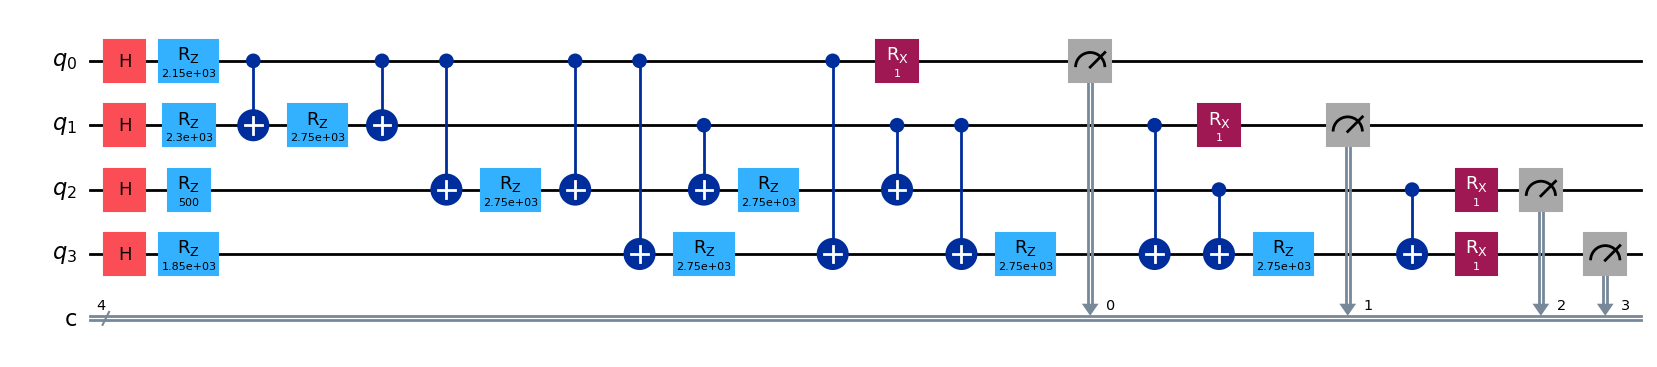


QAOA CIRCUIT STATISTICS
Qubits: 4
Classical bits: 4
Circuit depth: 19
Total gates: 34
Gate counts: OrderedDict({'cx': 12, 'rz': 10, 'h': 4, 'rx': 4, 'measure': 4})


In [21]:
# ============================================================
# BLOCK 10 — BUILD QAOA CIRCUIT
# ============================================================

print("================================================")
print("QAOA CIRCUIT CONSTRUCTION")
print("================================================")


# ------------------------------------------------------------
# 1. Number of qubits
# ------------------------------------------------------------

num_qubits = len(actions)

print("Number of qubits:", num_qubits)


# ------------------------------------------------------------
# 2. QAOA parameters
# ------------------------------------------------------------

p = 1

gamma = 0.5
beta = 0.5

print("QAOA layers (p):", p)
print("Gamma:", gamma)
print("Beta:", beta)


# ------------------------------------------------------------
# 3. Create quantum circuit
# ------------------------------------------------------------

qaoa_circuit = QuantumCircuit(
    num_qubits,
    num_qubits
)


# ------------------------------------------------------------
# 4. Initial superposition
#
# Put every qubit into |+>.
#
# This gives the circuit a superposition of candidate
# solutions.
# ------------------------------------------------------------

for qubit in range(num_qubits):

    qaoa_circuit.h(qubit)


# ------------------------------------------------------------
# 5. COST UNITARY
#
# The QUBO is:
#
#       sum Qii xi
#       +
#       sum Qij xi*xj
#
# We encode:
#
#       xi = (1 - Zi) / 2
#
# into quantum phase rotations.
# ------------------------------------------------------------

# Constant contribution is irrelevant for optimization,
# so we only need to implement the variable-dependent
# terms.


for i in range(num_qubits):

    # Qii * xi
    #
    # xi = (1 - Zi)/2
    #
    # Variable-dependent part:
    # -Qii * Zi / 2

    coefficient = Q[i, i]

    angle = -gamma * coefficient

    qaoa_circuit.rz(
        angle,
        i
    )


# ------------------------------------------------------------
# 6. Encode pairwise QUBO terms
# ------------------------------------------------------------

for i in range(num_qubits):

    for j in range(i + 1, num_qubits):

        coefficient = Q[i, j]

        if coefficient != 0:

            # Implement exp(-i * gamma * Qij * xi*xj)
            #
            # using CNOT-RZ-CNOT decomposition.

            angle = gamma * coefficient / 2

            qaoa_circuit.cx(
                i,
                j
            )

            qaoa_circuit.rz(
                angle,
                j
            )

            qaoa_circuit.cx(
                i,
                j
            )


# ------------------------------------------------------------
# 7. MIXER UNITARY
#
# The X mixer allows transitions between candidate
# binary solutions.
# ------------------------------------------------------------

for qubit in range(num_qubits):

    qaoa_circuit.rx(
        2 * beta,
        qubit
    )


# ------------------------------------------------------------
# 8. Measurement
# ------------------------------------------------------------

qaoa_circuit.measure(
    range(num_qubits),
    range(num_qubits)
)


# ------------------------------------------------------------
# 9. Display circuit
# ------------------------------------------------------------

print("\n================================================")
print("QAOA CIRCUIT")
print("================================================")

display(
    qaoa_circuit.draw(
        "mpl"
    )
)


# ------------------------------------------------------------
# 10. Circuit statistics
# ------------------------------------------------------------

print("\n================================================")
print("QAOA CIRCUIT STATISTICS")
print("================================================")

print(
    "Qubits:",
    qaoa_circuit.num_qubits
)

print(
    "Classical bits:",
    qaoa_circuit.num_clbits
)

print(
    "Circuit depth:",
    qaoa_circuit.depth()
)

print(
    "Total gates:",
    qaoa_circuit.size()
)

print(
    "Gate counts:",
    qaoa_circuit.count_ops()
)

In [22]:
# ============================================================
# BLOCK 11 — RUN QAOA ON QISKIT AER
# ============================================================

print("================================================")
print("RUNNING QAOA ON QISKIT AER")
print("================================================")


# ------------------------------------------------------------
# 1. Create Aer simulator
# ------------------------------------------------------------

simulator = AerSimulator()


# ------------------------------------------------------------
# 2. Transpile the QAOA circuit
# ------------------------------------------------------------

start_time = time.perf_counter()

compiled_qaoa = transpile(
    qaoa_circuit,
    simulator
)


# ------------------------------------------------------------
# 3. Execute the circuit
# ------------------------------------------------------------

shots = 2048

result = simulator.run(
    compiled_qaoa,
    shots=shots
).result()


execution_time = time.perf_counter() - start_time


# ------------------------------------------------------------
# 4. Get measurement counts
# ------------------------------------------------------------

counts = result.get_counts()


# ------------------------------------------------------------
# 5. Sort results by frequency
# ------------------------------------------------------------

sorted_counts = dict(
    sorted(
        counts.items(),
        key=lambda item: item[1],
        reverse=True
    )
)


# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("\n================================================")
print("QAOA MEASUREMENT RESULTS")
print("================================================")

for bitstring, count in sorted_counts.items():

    probability = count / shots

    print(
        f"{bitstring} : "
        f"{count} shots "
        f"({probability:.2%})"
    )


# ------------------------------------------------------------
# 7. Most frequently measured state
# ------------------------------------------------------------

most_frequent_bitstring = max(
    counts,
    key=counts.get
)

most_frequent_count = counts[
    most_frequent_bitstring
]

most_frequent_probability = (
    most_frequent_count / shots
)


# ------------------------------------------------------------
# 8. Execution information
# ------------------------------------------------------------

print("\n================================================")
print("QAOA EXECUTION INFORMATION")
print("================================================")

print(
    "Simulator:",
    "Qiskit Aer"
)

print(
    "Shots:",
    shots
)

print(
    "Most frequent bitstring:",
    most_frequent_bitstring
)

print(
    "Frequency:",
    most_frequent_count
)

print(
    "Probability:",
    f"{most_frequent_probability:.2%}"
)

print(
    "Execution time:",
    f"{execution_time:.6f} seconds"
)

RUNNING QAOA ON QISKIT AER

QAOA MEASUREMENT RESULTS
1101 : 303 shots (14.79%)
0011 : 288 shots (14.06%)
1011 : 230 shots (11.23%)
1110 : 206 shots (10.06%)
0100 : 181 shots (8.84%)
0000 : 166 shots (8.11%)
1100 : 128 shots (6.25%)
0010 : 111 shots (5.42%)
1001 : 93 shots (4.54%)
0111 : 84 shots (4.10%)
1000 : 73 shots (3.56%)
0110 : 67 shots (3.27%)
0001 : 55 shots (2.69%)
0101 : 52 shots (2.54%)
1010 : 9 shots (0.44%)
1111 : 2 shots (0.10%)

QAOA EXECUTION INFORMATION
Simulator: Qiskit Aer
Shots: 2048
Most frequent bitstring: 1101
Frequency: 303
Probability: 14.79%
Execution time: 0.117300 seconds


In [23]:
# ============================================================
# BLOCK 12 — DECODE QAOA RESULTS
# ============================================================

print("================================================")
print("DECODING QAOA RESULTS")
print("================================================")


# ------------------------------------------------------------
# 1. Decode a bitstring into selected actions
# ------------------------------------------------------------

def decode_bitstring(bitstring, actions):
    """
    Convert a QAOA measurement bitstring into the
    corresponding selected actions.

    Qiskit displays classical measurement strings with
    the highest-index classical bit on the left, so
    reverse the string to match q0, q1, q2, ...
    """

    bits = bitstring[::-1]

    selected_actions = []

    for i, bit in enumerate(bits):

        if bit == "1":
            selected_actions.append(actions[i])

    return selected_actions


# ------------------------------------------------------------
# 2. Analyze every measured state
# ------------------------------------------------------------

decoded_results = []

for bitstring, count in counts.items():

    selected_actions = decode_bitstring(
        bitstring,
        actions
    )

    # Valid solution requires exactly ONE selected action
    valid = len(selected_actions) == 1

    if valid:

        selected_action = selected_actions[0]

        cost = costs[selected_action]

        energy = qubo_energy(
            bitstring[::-1]
        )

    else:

        selected_action = None
        cost = None
        energy = qubo_energy(
            bitstring[::-1]
        )

    decoded_results.append({
        "bitstring": bitstring,
        "shots": count,
        "probability": count / shots,
        "selected_actions": selected_actions,
        "valid": valid,
        "cost": cost,
        "qubo_energy": energy
    })


decoded_df = pd.DataFrame(
    decoded_results
)


# ------------------------------------------------------------
# 3. Sort by measurement frequency
# ------------------------------------------------------------

decoded_df = decoded_df.sort_values(
    by="shots",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 4. Display decoded results
# ------------------------------------------------------------

print("\n================================================")
print("DECODED MEASUREMENT RESULTS")
print("================================================")

display(
    decoded_df
)


# ------------------------------------------------------------
# 5. Display valid QAOA solutions
# ------------------------------------------------------------

valid_results = decoded_df[
    decoded_df["valid"] == True
].copy()


print("\n================================================")
print("VALID QAOA SOLUTIONS")
print("================================================")

display(
    valid_results[
        [
            "bitstring",
            "shots",
            "probability",
            "selected_actions",
            "cost",
            "qubo_energy"
        ]
    ]
)


# ------------------------------------------------------------
# 6. Find the best valid measured solution
# ------------------------------------------------------------

if len(valid_results) > 0:

    best_qaoa_solution = valid_results.loc[
        valid_results["cost"].idxmin()
    ]

    print("\n================================================")
    print("BEST VALID QAOA SOLUTION")
    print("================================================")

    print(
        "Bitstring:",
        best_qaoa_solution["bitstring"]
    )

    print(
        "Selected action:",
        best_qaoa_solution["selected_actions"][0]
    )

    print(
        "Cost:",
        best_qaoa_solution["cost"]
    )

    print(
        "Measurement probability:",
        f"{best_qaoa_solution['probability']:.2%}"
    )

else:

    print(
        "\nNo valid exactly-one-action solution "
        "was measured."
    )

DECODING QAOA RESULTS

DECODED MEASUREMENT RESULTS


,bitstring,shots,probability,selected_actions,valid,cost,qubo_energy
0,1101,303,0.147949,"[train_search, flight_search, hotel_search]",False,NaN,24000.0
1,0011,288,0.140625,"[train_search, bus_search]",False,NaN,2100.0
2,1011,230,0.112305,"[train_search, bus_search, hotel_search]",False,NaN,20400.0
3,1110,206,0.100586,"[bus_search, flight_search, hotel_search]",False,NaN,23700.0
4,0100,181,0.088379,[flight_search],True,4500.0,-1000.0
5,0000,166,0.081055,[],False,NaN,0.0
6,1100,128,0.062500,"[flight_search, hotel_search]",False,NaN,6300.0
7,0010,111,0.054199,[bus_search],True,900.0,-4600.0
8,1001,93,0.045410,"[train_search, hotel_search]",False,NaN,3000.0
9,0111,84,0.041016,"[train_search, bus_search, flight_search]",False,NaN,23100.0



VALID QAOA SOLUTIONS


,bitstring,shots,probability,selected_actions,cost,qubo_energy
4,0100,181,0.088379,[flight_search],4500.0,-1000.0
7,0010,111,0.054199,[bus_search],900.0,-4600.0
10,1000,73,0.035645,[hotel_search],1800.0,-3700.0
12,0001,55,0.026855,[train_search],1200.0,-4300.0



BEST VALID QAOA SOLUTION
Bitstring: 0010
Selected action: bus_search
Cost: 900.0
Measurement probability: 5.42%


In [24]:
# ============================================================
# BLOCK 13 — QAOA PARAMETER OPTIMIZATION
# FIXED STATEVECTOR VERSION
# ============================================================

print("================================================")
print("QAOA PARAMETER OPTIMIZATION")
print("================================================")


# ------------------------------------------------------------
# 1. Build parameterized QAOA circuit
# ------------------------------------------------------------

def build_qaoa_circuit(gamma, beta, measure=True):

    circuit = QuantumCircuit(num_qubits)

    # Initial superposition
    for qubit in range(num_qubits):
        circuit.h(qubit)

    # --------------------------------------------------------
    # COST UNITARY
    # --------------------------------------------------------

    for i in range(num_qubits):

        coefficient = Q[i, i]

        angle = -gamma * coefficient

        circuit.rz(
            angle,
            i
        )

    # Pairwise QUBO terms
    for i in range(num_qubits):

        for j in range(i + 1, num_qubits):

            coefficient = Q[i, j]

            if coefficient != 0:

                angle = gamma * coefficient / 2

                circuit.cx(
                    i,
                    j
                )

                circuit.rz(
                    angle,
                    j
                )

                circuit.cx(
                    i,
                    j
                )

    # --------------------------------------------------------
    # MIXER
    # --------------------------------------------------------

    for qubit in range(num_qubits):

        circuit.rx(
            2 * beta,
            qubit
        )

    # --------------------------------------------------------
    # Measurement
    # --------------------------------------------------------

    if measure:

        circuit.measure_all()

    return circuit


# ------------------------------------------------------------
# 2. Calculate expected QUBO energy
# ------------------------------------------------------------

def expected_qaoa_energy(params):

    gamma = float(params[0])
    beta = float(params[1])

    # Build circuit WITHOUT measurements
    circuit = build_qaoa_circuit(
        gamma,
        beta,
        measure=False
    )

    # --------------------------------------------------------
    # Direct statevector calculation
    #
    # This avoids the Aer get_statevector issue.
    # --------------------------------------------------------

    statevector = Statevector.from_instruction(
        circuit
    )

    probabilities = (
        statevector.probabilities_dict()
    )

    expected_energy = 0.0

    for bitstring, probability in probabilities.items():

        # Reverse Qiskit's bit ordering so that:
        #
        # q0 -> x0
        # q1 -> x1
        # q2 -> x2
        # q3 -> x3

        logical_bitstring = bitstring[::-1]

        energy = qubo_energy(
            logical_bitstring
        )

        expected_energy += (
            probability * energy
        )

    return float(expected_energy)


# ------------------------------------------------------------
# 3. Test initial parameters
# ------------------------------------------------------------

initial_gamma = 0.5
initial_beta = 0.5

initial_energy = expected_qaoa_energy(
    [
        initial_gamma,
        initial_beta
    ]
)


print("\nInitial parameters")
print("------------------")

print(
    "Gamma:",
    initial_gamma
)

print(
    "Beta:",
    initial_beta
)

print(
    "Expected QUBO energy:",
    f"{initial_energy:.6f}"
)


# ------------------------------------------------------------
# 4. Optimize gamma and beta
# ------------------------------------------------------------

optimization_start = time.perf_counter()

optimization_result = minimize(
    expected_qaoa_energy,
    x0=[
        initial_gamma,
        initial_beta
    ],
    method="COBYLA",
    options={
        "maxiter": 40,
        "rhobeg": 0.5
    }
)

optimization_time = (
    time.perf_counter()
    - optimization_start
)


# ------------------------------------------------------------
# 5. Extract optimized parameters
# ------------------------------------------------------------

optimized_gamma = float(
    optimization_result.x[0]
)

optimized_beta = float(
    optimization_result.x[1]
)

optimized_energy = float(
    optimization_result.fun
)


# ------------------------------------------------------------
# 6. Display optimization results
# ------------------------------------------------------------

print("\n================================================")
print("OPTIMIZED QAOA PARAMETERS")
print("================================================")

print(
    "Optimized gamma:",
    f"{optimized_gamma:.6f}"
)

print(
    "Optimized beta:",
    f"{optimized_beta:.6f}"
)

print(
    "Optimized expected QUBO energy:",
    f"{optimized_energy:.6f}"
)

print(
    "Optimization successful:",
    optimization_result.success
)

print(
    "Optimization iterations:",
    optimization_result.nfev
)

print(
    "Optimization time:",
    f"{optimization_time:.4f} seconds"
)


# ------------------------------------------------------------
# 7. Compare initial and optimized energy
# ------------------------------------------------------------

print("\n================================================")
print("ENERGY COMPARISON")
print("================================================")

print(
    "Initial expected energy:",
    f"{initial_energy:.6f}"
)

print(
    "Optimized expected energy:",
    f"{optimized_energy:.6f}"
)

print(
    "Energy improvement:",
    f"{initial_energy - optimized_energy:.6f}"
)

QAOA PARAMETER OPTIMIZATION

Initial parameters
------------------
Gamma: 0.5
Beta: 0.5
Expected QUBO energy: 9775.414518

OPTIMIZED QAOA PARAMETERS
Optimized gamma: 0.956290
Optimized beta: 1.072209
Optimized expected QUBO energy: 1950.314637
Optimization successful: True
Optimization iterations: 28
Optimization time: 0.0977 seconds

ENERGY COMPARISON
Initial expected energy: 9775.414518
Optimized expected energy: 1950.314637
Energy improvement: 7825.099881


In [25]:
# ============================================================
# BLOCK 14 — RUN OPTIMIZED QAOA
# ============================================================

print("================================================")
print("RUNNING OPTIMIZED QAOA")
print("================================================")


# ------------------------------------------------------------
# 1. Build optimized QAOA circuit
# ------------------------------------------------------------

optimized_qaoa_circuit = build_qaoa_circuit(
    optimized_gamma,
    optimized_beta,
    measure=True
)


# ------------------------------------------------------------
# 2. Display optimized circuit statistics
# ------------------------------------------------------------

print("\n================================================")
print("OPTIMIZED CIRCUIT")
print("================================================")

print(
    "Gamma:",
    f"{optimized_gamma:.6f}"
)

print(
    "Beta:",
    f"{optimized_beta:.6f}"
)

print(
    "Qubits:",
    optimized_qaoa_circuit.num_qubits
)

print(
    "Circuit depth:",
    optimized_qaoa_circuit.depth()
)

print(
    "Total gates:",
    optimized_qaoa_circuit.size()
)


# ------------------------------------------------------------
# 3. Run on Qiskit Aer
# ------------------------------------------------------------

simulator = AerSimulator()

compiled_optimized = transpile(
    optimized_qaoa_circuit,
    simulator
)

shots_optimized = 2048

start_time = time.perf_counter()

optimized_result = simulator.run(
    compiled_optimized,
    shots=shots_optimized
).result()

optimized_execution_time = (
    time.perf_counter() - start_time
)


# ------------------------------------------------------------
# 4. Get measurement counts
# ------------------------------------------------------------

optimized_counts = (
    optimized_result.get_counts()
)


# ------------------------------------------------------------
# 5. Sort by frequency
# ------------------------------------------------------------

sorted_optimized_counts = dict(
    sorted(
        optimized_counts.items(),
        key=lambda item: item[1],
        reverse=True
    )
)


# ------------------------------------------------------------
# 6. Display measurement results
# ------------------------------------------------------------

print("\n================================================")
print("OPTIMIZED QAOA MEASUREMENTS")
print("================================================")

for bitstring, count in sorted_optimized_counts.items():

    probability = (
        count / shots_optimized
    )

    print(
        f"{bitstring} : "
        f"{count} shots "
        f"({probability:.2%})"
    )


# ------------------------------------------------------------
# 7. Most frequent state
# ------------------------------------------------------------

optimized_most_frequent = max(
    optimized_counts,
    key=optimized_counts.get
)

optimized_most_frequent_count = (
    optimized_counts[
        optimized_most_frequent
    ]
)

optimized_most_frequent_probability = (
    optimized_most_frequent_count
    / shots_optimized
)


# ------------------------------------------------------------
# 8. Display execution information
# ------------------------------------------------------------

print("\n================================================")
print("OPTIMIZED QAOA EXECUTION")
print("================================================")

print(
    "Shots:",
    shots_optimized
)

print(
    "Most frequent bitstring:",
    optimized_most_frequent
)

print(
    "Frequency:",
    optimized_most_frequent_count
)

print(
    "Probability:",
    f"{optimized_most_frequent_probability:.2%}"
)

print(
    "Execution time:",
    f"{optimized_execution_time:.6f} seconds"
)

RUNNING OPTIMIZED QAOA

OPTIMIZED CIRCUIT
Gamma: 0.956290
Beta: 1.072209
Qubits: 4
Circuit depth: 19
Total gates: 34

OPTIMIZED QAOA MEASUREMENTS
0001 : 363 shots (17.72%)
0000 : 285 shots (13.92%)
0010 : 276 shots (13.48%)
1000 : 272 shots (13.28%)
0100 : 142 shots (6.93%)
1001 : 121 shots (5.91%)
0101 : 116 shots (5.66%)
0011 : 98 shots (4.79%)
1010 : 85 shots (4.15%)
1111 : 72 shots (3.52%)
1101 : 52 shots (2.54%)
0110 : 49 shots (2.39%)
0111 : 46 shots (2.25%)
1100 : 34 shots (1.66%)
1110 : 21 shots (1.03%)
1011 : 16 shots (0.78%)

OPTIMIZED QAOA EXECUTION
Shots: 2048
Most frequent bitstring: 0001
Frequency: 363
Probability: 17.72%
Execution time: 0.005013 seconds


INITIAL vs OPTIMIZED QAOA

CLASSICAL OPTIMUM
Action: bus_search
Cost: 900
Logical bitstring: 0100
Measured bitstring: 0010

QAOA COMPARISON
Initial QAOA probability of bus_search: 5.42%
Optimized QAOA probability of bus_search: 13.48%
Absolute probability improvement: 8.06%
Relative improvement: 148.65%

Initial valid-solution probability: 20.51%
Optimized valid-solution probability: 51.42%

COMPARISON TABLE


,Metric,Initial QAOA,Optimized QAOA
0,Optimal action probability,0.054199,0.134766
1,Valid solution probability,0.205078,0.514160
2,Execution time (seconds),0.117300,0.005013
3,Circuit depth,19.000000,19.000000
4,Total gates,34.000000,34.000000


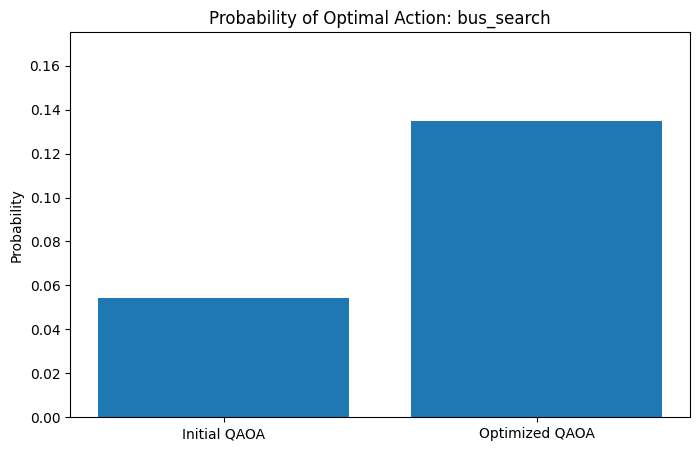

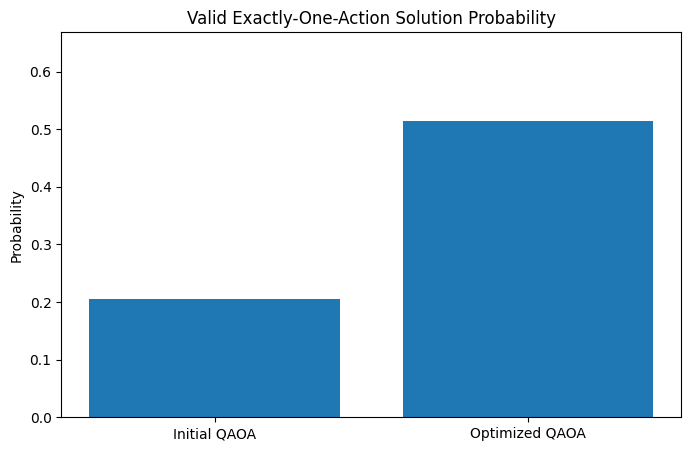


BLOCK 15 SUMMARY
Classical optimum: bus_search
Classical cost: 900
Initial QAOA probability: 5.42%
Optimized QAOA probability: 13.48%
Optimized parameters:
  Gamma = 0.956290
  Beta  = 1.072209


In [26]:
# ============================================================
# BLOCK 15 — INITIAL vs OPTIMIZED QAOA COMPARISON
# ============================================================

print("================================================")
print("INITIAL vs OPTIMIZED QAOA")
print("================================================")


# ------------------------------------------------------------
# 1. Optimal logical solution
# ------------------------------------------------------------

optimal_action = classical_baseline["selected_action"]

optimal_cost = classical_baseline["cost"]

# In our logical x0,x1,x2,x3 representation:
optimal_index = actions.index(optimal_action)

optimal_logical_bitstring = (
    "0" * optimal_index
    + "1"
    + "0" * (num_qubits - optimal_index - 1)
)

# Convert logical ordering to Qiskit displayed ordering
optimal_display_bitstring = (
    optimal_logical_bitstring[::-1]
)


print("\n================================================")
print("CLASSICAL OPTIMUM")
print("================================================")

print(
    "Action:",
    optimal_action
)

print(
    "Cost:",
    optimal_cost
)

print(
    "Logical bitstring:",
    optimal_logical_bitstring
)

print(
    "Measured bitstring:",
    optimal_display_bitstring
)


# ------------------------------------------------------------
# 2. Initial QAOA probability
# ------------------------------------------------------------

initial_optimal_count = counts.get(
    optimal_display_bitstring,
    0
)

initial_optimal_probability = (
    initial_optimal_count / shots
)


# ------------------------------------------------------------
# 3. Optimized QAOA probability
# ------------------------------------------------------------

optimized_optimal_count = optimized_counts.get(
    optimal_display_bitstring,
    0
)

optimized_optimal_probability = (
    optimized_optimal_count / shots_optimized
)


# ------------------------------------------------------------
# 4. Calculate improvement
# ------------------------------------------------------------

probability_improvement = (
    optimized_optimal_probability
    - initial_optimal_probability
)

if initial_optimal_probability > 0:

    relative_improvement = (
        probability_improvement
        / initial_optimal_probability
    ) * 100

else:

    relative_improvement = float("inf")


# ------------------------------------------------------------
# 5. Calculate valid-solution probability
# ------------------------------------------------------------

def valid_solution_probability(
    measurement_counts,
    total_shots
):

    valid_shots = 0

    for bitstring, count in measurement_counts.items():

        selected = decode_bitstring(
            bitstring,
            actions
        )

        if len(selected) == 1:
            valid_shots += count

    return valid_shots / total_shots


initial_valid_probability = (
    valid_solution_probability(
        counts,
        shots
    )
)

optimized_valid_probability = (
    valid_solution_probability(
        optimized_counts,
        shots_optimized
    )
)


# ------------------------------------------------------------
# 6. Display comparison
# ------------------------------------------------------------

print("\n================================================")
print("QAOA COMPARISON")
print("================================================")

print(
    f"Initial QAOA probability of "
    f"{optimal_action}: "
    f"{initial_optimal_probability:.2%}"
)

print(
    f"Optimized QAOA probability of "
    f"{optimal_action}: "
    f"{optimized_optimal_probability:.2%}"
)

print(
    "Absolute probability improvement:",
    f"{probability_improvement:.2%}"
)

if relative_improvement != float("inf"):

    print(
        "Relative improvement:",
        f"{relative_improvement:.2f}%"
    )

print(
    "\nInitial valid-solution probability:",
    f"{initial_valid_probability:.2%}"
)

print(
    "Optimized valid-solution probability:",
    f"{optimized_valid_probability:.2%}"
)


# ------------------------------------------------------------
# 7. Create comparison dataframe
# ------------------------------------------------------------

comparison_df = pd.DataFrame({

    "Metric": [
        "Optimal action probability",
        "Valid solution probability",
        "Execution time (seconds)",
        "Circuit depth",
        "Total gates"
    ],

    "Initial QAOA": [
        initial_optimal_probability,
        initial_valid_probability,
        execution_time,
        qaoa_circuit.depth(),
        qaoa_circuit.size()
    ],

    "Optimized QAOA": [
        optimized_optimal_probability,
        optimized_valid_probability,
        optimized_execution_time,
        optimized_qaoa_circuit.depth(),
        optimized_qaoa_circuit.size()
    ]
})


print("\n================================================")
print("COMPARISON TABLE")
print("================================================")

display(comparison_df)


# ------------------------------------------------------------
# 8. Plot optimal-state probability
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    ["Initial QAOA", "Optimized QAOA"],
    [
        initial_optimal_probability,
        optimized_optimal_probability
    ]
)

plt.ylabel("Probability")

plt.title(
    f"Probability of Optimal Action: {optimal_action}"
)

plt.ylim(
    0,
    max(
        optimized_optimal_probability,
        initial_optimal_probability
    ) * 1.3
)

plt.show()


# ------------------------------------------------------------
# 9. Plot valid-solution probability
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    ["Initial QAOA", "Optimized QAOA"],
    [
        initial_valid_probability,
        optimized_valid_probability
    ]
)

plt.ylabel("Probability")

plt.title(
    "Valid Exactly-One-Action Solution Probability"
)

plt.ylim(
    0,
    max(
        optimized_valid_probability,
        initial_valid_probability
    ) * 1.3
)

plt.show()


# ------------------------------------------------------------
# 10. Final summary
# ------------------------------------------------------------

print("\n================================================")
print("BLOCK 15 SUMMARY")
print("================================================")

print(
    "Classical optimum:",
    optimal_action
)

print(
    "Classical cost:",
    optimal_cost
)

print(
    "Initial QAOA probability:",
    f"{initial_optimal_probability:.2%}"
)

print(
    "Optimized QAOA probability:",
    f"{optimized_optimal_probability:.2%}"
)

print(
    "Optimized parameters:"
)

print(
    "  Gamma =",
    f"{optimized_gamma:.6f}"
)

print(
    "  Beta  =",
    f"{optimized_beta:.6f}"
)

GROVER SEARCH / AMPLITUDE AMPLIFICATION

GROVER CIRCUIT


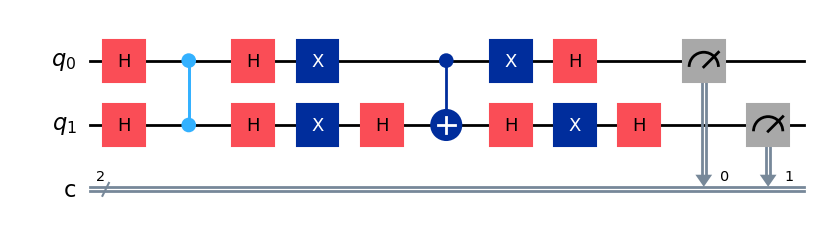


GROVER CIRCUIT STATISTICS
Qubits: 2
Circuit depth: 10
Total gates: 16
Gate counts: OrderedDict({'h': 8, 'x': 4, 'measure': 2, 'cz': 1, 'cx': 1})

GROVER MEASUREMENT RESULTS
11 : 2048 shots (100.00%)

GROVER TARGET RESULT
Target state: 11
Target shots: 2048
Target probability: 100.00%
Execution time: 0.004316 seconds


In [27]:
# ============================================================
# BLOCK 16 — GROVER SEARCH / AMPLITUDE AMPLIFICATION
# ============================================================

print("================================================")
print("GROVER SEARCH / AMPLITUDE AMPLIFICATION")
print("================================================")


# ------------------------------------------------------------
# 1. Create a 2-qubit Grover circuit
# ------------------------------------------------------------

grover_circuit = QuantumCircuit(2, 2)


# ------------------------------------------------------------
# 2. Initial superposition
#
# Create equal probability for:
#
# 00, 01, 10, 11
# ------------------------------------------------------------

grover_circuit.h(0)
grover_circuit.h(1)

# ------------------------------------------------------------
# 3. Oracle
#
# Target state = |11>
#
# A controlled-Z gate flips the phase of |11>.
# ------------------------------------------------------------

grover_circuit.cz(0, 1)


# ------------------------------------------------------------
# 4. Grover diffuser
#
# The diffuser amplifies the amplitude of the marked
# state.
# ------------------------------------------------------------

grover_circuit.h(0)
grover_circuit.h(1)

grover_circuit.x(0)
grover_circuit.x(1)

grover_circuit.h(1)

grover_circuit.cx(0, 1)

grover_circuit.h(1)

grover_circuit.x(0)
grover_circuit.x(1)

grover_circuit.h(0)
grover_circuit.h(1)


# ------------------------------------------------------------
# 5. Measurement
# ------------------------------------------------------------

grover_circuit.measure(
    [0, 1],
    [0, 1]
)


# ------------------------------------------------------------
# 6. Display circuit
# ------------------------------------------------------------

print("\n================================================")
print("GROVER CIRCUIT")
print("================================================")

display(
    grover_circuit.draw("mpl")
)


# ------------------------------------------------------------
# 7. Circuit statistics
# ------------------------------------------------------------

print("\n================================================")
print("GROVER CIRCUIT STATISTICS")
print("================================================")

print(
    "Qubits:",
    grover_circuit.num_qubits
)

print(
    "Circuit depth:",
    grover_circuit.depth()
)

print(
    "Total gates:",
    grover_circuit.size()
)

print(
    "Gate counts:",
    grover_circuit.count_ops()
)


# ------------------------------------------------------------
# 8. Run Grover on Qiskit Aer
# ------------------------------------------------------------

grover_simulator = AerSimulator()

compiled_grover = transpile(
    grover_circuit,
    grover_simulator
)

grover_shots = 2048

grover_start = time.perf_counter()

grover_result = grover_simulator.run(
    compiled_grover,
    shots=grover_shots
).result()

grover_execution_time = (
    time.perf_counter() - grover_start
)


# ------------------------------------------------------------
# 9. Get measurement counts
# ------------------------------------------------------------

grover_counts = (
    grover_result.get_counts()
)


# ------------------------------------------------------------
# 10. Sort results
# ------------------------------------------------------------

sorted_grover_counts = dict(
    sorted(
        grover_counts.items(),
        key=lambda item: item[1],
        reverse=True
    )
)


# ------------------------------------------------------------
# 11. Display results
# ------------------------------------------------------------

print("\n================================================")
print("GROVER MEASUREMENT RESULTS")
print("================================================")

for bitstring, count in sorted_grover_counts.items():

    probability = (
        count / grover_shots
    )

    print(
        f"{bitstring} : "
        f"{count} shots "
        f"({probability:.2%})"
    )


# ------------------------------------------------------------
# 12. Target-state probability
# ------------------------------------------------------------

target_state = "11"

target_count = grover_counts.get(
    target_state,
    0
)

target_probability = (
    target_count / grover_shots
)


print("\n================================================")
print("GROVER TARGET RESULT")
print("================================================")

print(
    "Target state:",
    target_state
)

print(
    "Target shots:",
    target_count
)

print(
    "Target probability:",
    f"{target_probability:.2%}"
)

print(
    "Execution time:",
    f"{grover_execution_time:.6f} seconds"
)

VARIATIONAL QUANTUM CIRCUIT

PARAMETERIZED VQC


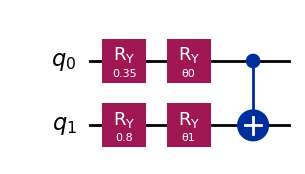


VQC CIRCUIT STATISTICS
Qubits: 2
Circuit depth: 3
Total gates: 5
Gate counts: OrderedDict({'ry': 4, 'cx': 1})

VQC MEASUREMENT RESULTS
10 : 1031 shots (50.34%)
00 : 584 shots (28.52%)
01 : 295 shots (14.40%)
11 : 138 shots (6.74%)

VQC EXECUTION INFORMATION
Shots: 2048
Feature vector: [0.35, 0.8]
θ0: 0.6
θ1: 1.1
Execution time: 0.008117 seconds


In [28]:
# ============================================================
# BLOCK 17 — VARIATIONAL QUANTUM CIRCUIT (VQC)
# ============================================================

print("================================================")
print("VARIATIONAL QUANTUM CIRCUIT")
print("================================================")


# ------------------------------------------------------------
# 1. Create parameterized VQC
# ------------------------------------------------------------

num_vqc_qubits = 2

vqc = QuantumCircuit(
    num_vqc_qubits
)


# ------------------------------------------------------------
# 2. Define trainable parameters
# ------------------------------------------------------------

theta_0 = Parameter("θ0")
theta_1 = Parameter("θ1")


# ------------------------------------------------------------
# 3. Feature encoding
#
# A small example feature vector is encoded using
# rotation gates.
# ------------------------------------------------------------

feature_vector = [
    0.35,
    0.80
]

vqc.ry(
    feature_vector[0],
    0
)

vqc.ry(
    feature_vector[1],
    1
)


# ------------------------------------------------------------
# 4. Variational layer
# ------------------------------------------------------------

vqc.ry(
    theta_0,
    0
)

vqc.ry(
    theta_1,
    1
)


# ------------------------------------------------------------
# 5. Entanglement
# ------------------------------------------------------------

vqc.cx(
    0,
    1
)


# ------------------------------------------------------------
# 6. Display parameterized circuit
# ------------------------------------------------------------

print("\n================================================")
print("PARAMETERIZED VQC")
print("================================================")

display(
    vqc.draw("mpl")
)


# ------------------------------------------------------------
# 7. Circuit statistics
# ------------------------------------------------------------

print("\n================================================")
print("VQC CIRCUIT STATISTICS")
print("================================================")

print(
    "Qubits:",
    vqc.num_qubits
)

print(
    "Circuit depth:",
    vqc.depth()
)

print(
    "Total gates:",
    vqc.size()
)

print(
    "Gate counts:",
    vqc.count_ops()
)


# ------------------------------------------------------------
# 8. Assign example variational parameters
# ------------------------------------------------------------

parameter_values = {
    theta_0: 0.60,
    theta_1: 1.10
}

bound_vqc = vqc.assign_parameters(
    parameter_values
)


# ------------------------------------------------------------
# 9. Add measurements
# ------------------------------------------------------------

measured_vqc = bound_vqc.copy()

measured_vqc.measure_all()


# ------------------------------------------------------------
# 10. Run VQC on Aer
# ------------------------------------------------------------

vqc_simulator = AerSimulator()

compiled_vqc = transpile(
    measured_vqc,
    vqc_simulator
)

vqc_shots = 2048

vqc_start = time.perf_counter()

vqc_result = vqc_simulator.run(
    compiled_vqc,
    shots=vqc_shots
).result()

vqc_execution_time = (
    time.perf_counter() - vqc_start
)


# ------------------------------------------------------------
# 11. Get measurement results
# ------------------------------------------------------------

vqc_counts = (
    vqc_result.get_counts()
)


# ------------------------------------------------------------
# 12. Sort results
# ------------------------------------------------------------

sorted_vqc_counts = dict(
    sorted(
        vqc_counts.items(),
        key=lambda item: item[1],
        reverse=True
    )
)


# ------------------------------------------------------------
# 13. Display measurement results
# ------------------------------------------------------------

print("\n================================================")
print("VQC MEASUREMENT RESULTS")
print("================================================")

for bitstring, count in sorted_vqc_counts.items():

    probability = (
        count / vqc_shots
    )

    print(
        f"{bitstring} : "
        f"{count} shots "
        f"({probability:.2%})"
    )


# ------------------------------------------------------------
# 14. Display execution information
# ------------------------------------------------------------

print("\n================================================")
print("VQC EXECUTION INFORMATION")
print("================================================")

print(
    "Shots:",
    vqc_shots
)

print(
    "Feature vector:",
    feature_vector
)

print(
    "θ0:",
    parameter_values[theta_0]
)

print(
    "θ1:",
    parameter_values[theta_1]
)

print(
    "Execution time:",
    f"{vqc_execution_time:.6f} seconds"
)

QUANTUM SIMILARITY / RETRIEVAL

INPUT FEATURE VECTORS
Query: [0.35 0.8 ]
Candidate_A: [0.36 0.78]
Candidate_B: [2.5 2.8]

QUANTUM SIMILARITY RESULTS


,candidate,quantum_fidelity
0,Candidate_A,0.999014
1,Candidate_B,0.777901



BEST QUANTUM RETRIEVAL RESULT
Most similar candidate: Candidate_A
Quantum fidelity: 0.999014


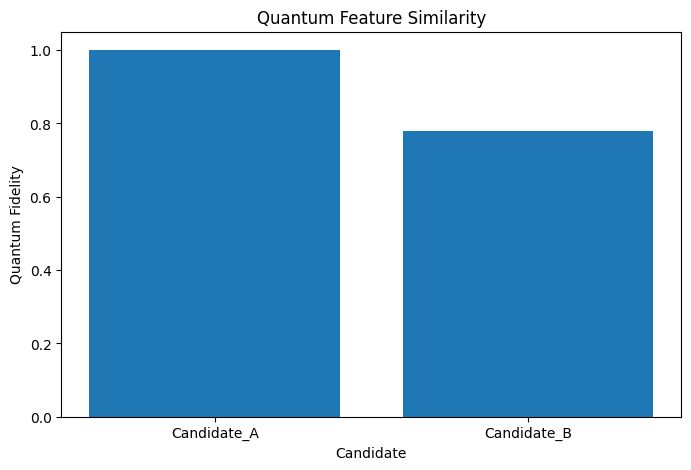


QUERY QUANTUM ENCODING CIRCUIT


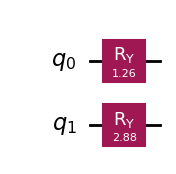

In [29]:
# ============================================================
# BLOCK 18 — QUANTUM SIMILARITY / RETRIEVAL
# ============================================================

print("================================================")
print("QUANTUM SIMILARITY / RETRIEVAL")
print("================================================")


# ------------------------------------------------------------
# 1. Define query and candidate feature vectors
# ------------------------------------------------------------

query_vector = np.array([
    0.35,
    0.80
])

candidate_vectors = {

    "Candidate_A": np.array([
        0.36,
        0.78
    ]),

    "Candidate_B": np.array([
        2.50,
        2.80
    ])
}


print("\n================================================")
print("INPUT FEATURE VECTORS")
print("================================================")

print(
    "Query:",
    query_vector
)

for name, vector in candidate_vectors.items():

    print(
        name + ":",
        vector
    )


# ------------------------------------------------------------
# 2. Normalize feature vectors
# ------------------------------------------------------------

def normalize_vector(vector):

    norm = np.linalg.norm(vector)

    if norm == 0:
        return vector

    return vector / norm


# ------------------------------------------------------------
# 3. Encode feature vector into a quantum state
#
# Each feature controls an RY rotation.
# ------------------------------------------------------------

def encode_features(vector):

    normalized = normalize_vector(
        vector
    )

    circuit = QuantumCircuit(2)

    circuit.ry(
        normalized[0] * np.pi,
        0
    )

    circuit.ry(
        normalized[1] * np.pi,
        1
    )

    return circuit


# ------------------------------------------------------------
# 4. Generate quantum states
# ------------------------------------------------------------

query_circuit = encode_features(
    query_vector
)

query_state = Statevector.from_instruction(
    query_circuit
)


candidate_states = {}

for name, vector in candidate_vectors.items():

    circuit = encode_features(
        vector
    )

    candidate_states[name] = (
        Statevector.from_instruction(
            circuit
        )
    )


# ------------------------------------------------------------
# 5. Calculate quantum fidelity
# ------------------------------------------------------------

def quantum_fidelity(
    state_a,
    state_b
):

    overlap = np.vdot(
        state_a.data,
        state_b.data
    )

    fidelity = (
        np.abs(overlap) ** 2
    )

    return float(
        np.real(fidelity)
    )


similarity_results = []

for name, state in candidate_states.items():

    fidelity = quantum_fidelity(
        query_state,
        state
    )

    similarity_results.append({

        "candidate": name,

        "quantum_fidelity": fidelity
    })


# ------------------------------------------------------------
# 6. Create results dataframe
# ------------------------------------------------------------

similarity_df = pd.DataFrame(
    similarity_results
)

similarity_df = similarity_df.sort_values(
    by="quantum_fidelity",
    ascending=False
).reset_index(
    drop=True
)


# ------------------------------------------------------------
# 7. Display similarity results
# ------------------------------------------------------------

print("\n================================================")
print("QUANTUM SIMILARITY RESULTS")
print("================================================")

display(
    similarity_df
)


# ------------------------------------------------------------
# 8. Select highest similarity candidate
# ------------------------------------------------------------

best_candidate = (
    similarity_df.iloc[0]["candidate"]
)

best_similarity = (
    similarity_df.iloc[0]["quantum_fidelity"]
)


print("\n================================================")
print("BEST QUANTUM RETRIEVAL RESULT")
print("================================================")

print(
    "Most similar candidate:",
    best_candidate
)

print(
    "Quantum fidelity:",
    f"{best_similarity:.6f}"
)


# ------------------------------------------------------------
# 9. Visualize similarity
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.bar(
    similarity_df["candidate"],
    similarity_df["quantum_fidelity"]
)

plt.xlabel(
    "Candidate"
)

plt.ylabel(
    "Quantum Fidelity"
)

plt.title(
    "Quantum Feature Similarity"
)

plt.ylim(
    0,
    1.05
)

plt.show()


# ------------------------------------------------------------
# 10. Display the query encoding circuit
# ------------------------------------------------------------

print("\n================================================")
print("QUERY QUANTUM ENCODING CIRCUIT")
print("================================================")

display(
    query_circuit.draw("mpl")
)

In [30]:
# ============================================================
# BLOCK 19 — NISQ NOISE EXPERIMENT
# ============================================================

from qiskit_aer.noise import (
    NoiseModel,
    depolarizing_error,
    ReadoutError
)


print("================================================")
print("NISQ NOISE EXPERIMENT")
print("================================================")


# ------------------------------------------------------------
# 1. Create a noise model
# ------------------------------------------------------------

noise_model = NoiseModel()


# ------------------------------------------------------------
# 2. Single-qubit depolarizing noise
#
# This models errors occurring during single-qubit
# operations.
# ------------------------------------------------------------

single_qubit_error = depolarizing_error(
    0.01,
    1
)


# ------------------------------------------------------------
# 3. Two-qubit depolarizing noise
#
# Two-qubit gates are generally more error-prone,
# so we use a slightly larger error probability.
# ------------------------------------------------------------

two_qubit_error = depolarizing_error(
    0.02,
    2
)


# ------------------------------------------------------------
# 4. Add noise to the model
# ------------------------------------------------------------

noise_model.add_all_qubit_quantum_error(
    single_qubit_error,
    [
        "h",
        "rx",
        "ry",
        "rz"
    ]
)

noise_model.add_all_qubit_quantum_error(
    two_qubit_error,
    [
        "cx"
    ]
)


# ------------------------------------------------------------
# 5. Add readout error
# ------------------------------------------------------------

readout_error = ReadoutError([
    [
        0.98,
        0.02
    ],
    [
        0.02,
        0.98
    ]
])


noise_model.add_all_qubit_readout_error(
    readout_error
)


# ------------------------------------------------------------
# 6. Display noise model
# ------------------------------------------------------------

print("\n================================================")
print("NOISE MODEL")
print("================================================")

print(
    "Single-qubit depolarizing error:",
    "1%"
)

print(
    "Two-qubit depolarizing error:",
    "2%"
)

print(
    "Readout error:",
    "2%"
)


# ------------------------------------------------------------
# 7. Run ideal QAOA
# ------------------------------------------------------------

ideal_simulator = AerSimulator()

ideal_compiled = transpile(
    optimized_qaoa_circuit,
    ideal_simulator
)

noise_shots = 2048

ideal_start = time.perf_counter()

ideal_noise_test_result = (
    ideal_simulator.run(
        ideal_compiled,
        shots=noise_shots
    ).result()
)

ideal_noise_test_time = (
    time.perf_counter() - ideal_start
)


ideal_noise_test_counts = (
    ideal_noise_test_result.get_counts()
)


# ------------------------------------------------------------
# 8. Run noisy QAOA
# ------------------------------------------------------------

noisy_simulator = AerSimulator(
    noise_model=noise_model
)

noisy_compiled = transpile(
    optimized_qaoa_circuit,
    noisy_simulator
)

noisy_start = time.perf_counter()

noisy_result = noisy_simulator.run(
    noisy_compiled,
    shots=noise_shots
).result()

noisy_execution_time = (
    time.perf_counter() - noisy_start
)


noisy_counts = (
    noisy_result.get_counts()
)


# ------------------------------------------------------------
# 9. Optimal state
# ------------------------------------------------------------

optimal_state = (
    optimal_display_bitstring
)


# ------------------------------------------------------------
# 10. Calculate probabilities
# ------------------------------------------------------------

ideal_optimal_probability = (
    ideal_noise_test_counts.get(
        optimal_state,
        0
    )
    / noise_shots
)


noisy_optimal_probability = (
    noisy_counts.get(
        optimal_state,
        0
    )
    / noise_shots
)


# ------------------------------------------------------------
# 11. Calculate noise impact
# ------------------------------------------------------------

noise_probability_change = (
    noisy_optimal_probability
    - ideal_optimal_probability
)


noise_probability_loss = (
    ideal_optimal_probability
    - noisy_optimal_probability
)


# ------------------------------------------------------------
# 12. Display results
# ------------------------------------------------------------

print("\n================================================")
print("IDEAL vs NOISY QAOA")
print("================================================")

print(
    "Optimal action:",
    optimal_action
)

print(
    "Optimal measured state:",
    optimal_state
)

print(
    "\nIdeal probability:",
    f"{ideal_optimal_probability:.2%}"
)

print(
    "Noisy probability:",
    f"{noisy_optimal_probability:.2%}"
)

print(
    "Probability change:",
    f"{noise_probability_change:.2%}"
)

print(
    "Probability loss:",
    f"{noise_probability_loss:.2%}"
)


# ------------------------------------------------------------
# 13. Display execution times
# ------------------------------------------------------------

print("\n================================================")
print("EXECUTION TIMES")
print("================================================")

print(
    "Ideal simulation:",
    f"{ideal_noise_test_time:.6f} seconds"
)

print(
    "Noisy simulation:",
    f"{noisy_execution_time:.6f} seconds"
)


# ------------------------------------------------------------
# 14. Display noisy measurement distribution
# ------------------------------------------------------------

print("\n================================================")
print("NOISY QAOA MEASUREMENTS")
print("================================================")

sorted_noisy_counts = dict(
    sorted(
        noisy_counts.items(),
        key=lambda item: item[1],
        reverse=True
    )
)

for bitstring, count in sorted_noisy_counts.items():

    probability = (
        count / noise_shots
    )

    print(
        f"{bitstring} : "
        f"{count} shots "
        f"({probability:.2%})"
    )

NISQ NOISE EXPERIMENT

NOISE MODEL
Single-qubit depolarizing error: 1%
Two-qubit depolarizing error: 2%
Readout error: 2%

IDEAL vs NOISY QAOA
Optimal action: bus_search
Optimal measured state: 0010

Ideal probability: 13.82%
Noisy probability: 11.62%
Probability change: -2.20%
Probability loss: 2.20%

EXECUTION TIMES
Ideal simulation: 0.014846 seconds
Noisy simulation: 0.013004 seconds

NOISY QAOA MEASUREMENTS
0001 : 328 shots (16.02%)
0010 : 238 shots (11.62%)
0000 : 237 shots (11.57%)
1000 : 227 shots (11.08%)
0100 : 154 shots (7.52%)
1010 : 129 shots (6.30%)
1001 : 116 shots (5.66%)
0011 : 116 shots (5.66%)
0101 : 109 shots (5.32%)
0110 : 75 shots (3.66%)
1100 : 62 shots (3.03%)
1101 : 59 shots (2.88%)
0111 : 56 shots (2.73%)
1111 : 53 shots (2.59%)
1011 : 52 shots (2.54%)
1110 : 37 shots (1.81%)


IDEAL vs NOISY QAOA ANALYSIS

NOISE COMPARISON TABLE


,Condition,Optimal_State_Probability,Execution_Time
0,Ideal,0.138184,0.014846
1,Noisy,0.116211,0.013004



NOISE IMPACT
Ideal optimal-state probability: 13.82%
Noisy optimal-state probability: 11.62%
Absolute probability loss: 2.20%
Relative probability degradation: 15.90%


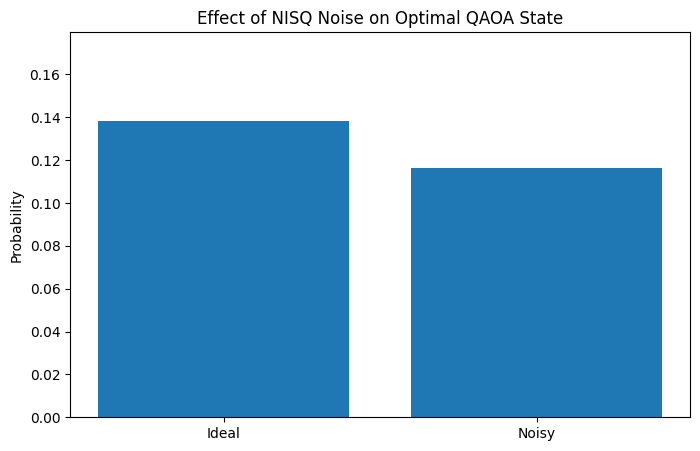

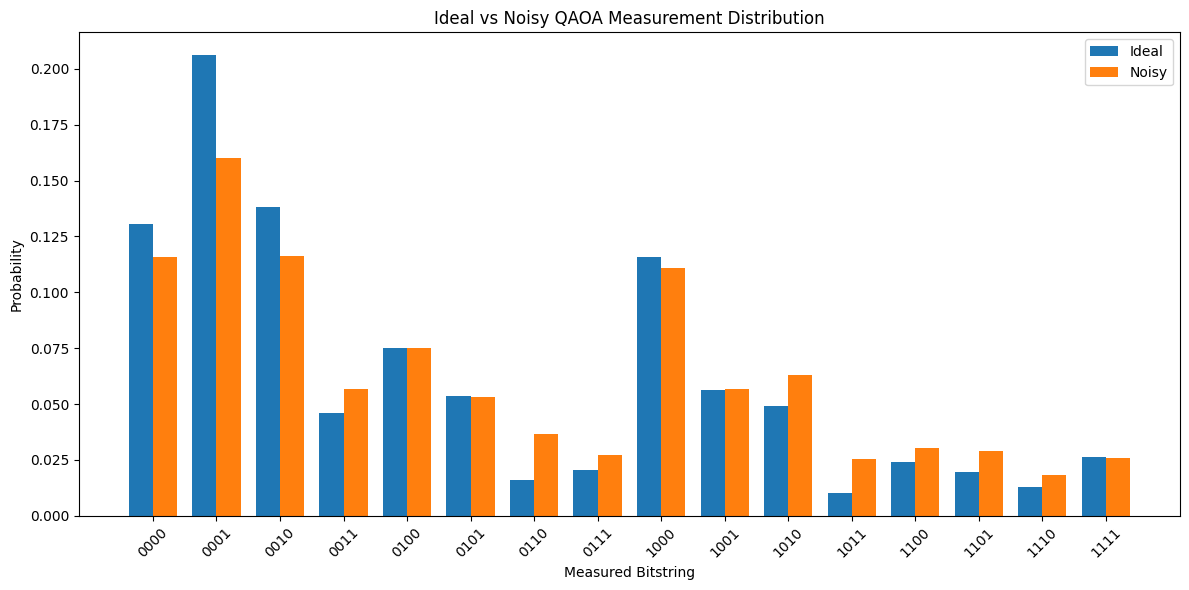


BLOCK 20 SUMMARY
Optimal action: bus_search
Optimal state: 0010
Ideal probability: 13.82%
Noisy probability: 11.62%
Probability loss: 2.20%
Relative degradation: 15.90%


In [31]:
# ============================================================
# BLOCK 20 — IDEAL vs NOISY ANALYSIS
# ============================================================

print("================================================")
print("IDEAL vs NOISY QAOA ANALYSIS")
print("================================================")


# ------------------------------------------------------------
# 1. Create comparison dataframe
# ------------------------------------------------------------

noise_comparison_df = pd.DataFrame({

    "Condition": [
        "Ideal",
        "Noisy"
    ],

    "Optimal_State_Probability": [
        ideal_optimal_probability,
        noisy_optimal_probability
    ],

    "Execution_Time": [
        ideal_noise_test_time,
        noisy_execution_time
    ]
})


# ------------------------------------------------------------
# 2. Display comparison table
# ------------------------------------------------------------

print("\n================================================")
print("NOISE COMPARISON TABLE")
print("================================================")

display(
    noise_comparison_df
)


# ------------------------------------------------------------
# 3. Calculate degradation percentage
# ------------------------------------------------------------

if ideal_optimal_probability > 0:

    degradation_percentage = (
        (
            ideal_optimal_probability
            - noisy_optimal_probability
        )
        / ideal_optimal_probability
    ) * 100

else:

    degradation_percentage = 0


print("\n================================================")
print("NOISE IMPACT")
print("================================================")

print(
    "Ideal optimal-state probability:",
    f"{ideal_optimal_probability:.2%}"
)

print(
    "Noisy optimal-state probability:",
    f"{noisy_optimal_probability:.2%}"
)

print(
    "Absolute probability loss:",
    f"{noise_probability_loss:.2%}"
)

print(
    "Relative probability degradation:",
    f"{degradation_percentage:.2f}%"
)


# ------------------------------------------------------------
# 4. Plot ideal vs noisy probability
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.bar(
    ["Ideal", "Noisy"],
    [
        ideal_optimal_probability,
        noisy_optimal_probability
    ]
)

plt.ylabel(
    "Probability"
)

plt.title(
    "Effect of NISQ Noise on Optimal QAOA State"
)

plt.ylim(
    0,
    max(
        ideal_optimal_probability,
        noisy_optimal_probability
    ) * 1.3
)

plt.show()


# ------------------------------------------------------------
# 5. Plot measurement distributions
# ------------------------------------------------------------

all_states = sorted(
    set(
        ideal_noise_test_counts.keys()
    ).union(
        noisy_counts.keys()
    )
)


ideal_probabilities = [
    ideal_noise_test_counts.get(
        state,
        0
    ) / noise_shots
    for state in all_states
]


noisy_probabilities = [
    noisy_counts.get(
        state,
        0
    ) / noise_shots
    for state in all_states
]


x = np.arange(
    len(all_states)
)

width = 0.38


plt.figure(
    figsize=(12, 6)
)

plt.bar(
    x - width / 2,
    ideal_probabilities,
    width,
    label="Ideal"
)

plt.bar(
    x + width / 2,
    noisy_probabilities,
    width,
    label="Noisy"
)

plt.xlabel(
    "Measured Bitstring"
)

plt.ylabel(
    "Probability"
)

plt.title(
    "Ideal vs Noisy QAOA Measurement Distribution"
)

plt.xticks(
    x,
    all_states,
    rotation=45
)

plt.legend()

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 6. Final summary
# ------------------------------------------------------------

print("\n================================================")
print("BLOCK 20 SUMMARY")
print("================================================")

print(
    "Optimal action:",
    optimal_action
)

print(
    "Optimal state:",
    optimal_state
)

print(
    "Ideal probability:",
    f"{ideal_optimal_probability:.2%}"
)

print(
    "Noisy probability:",
    f"{noisy_optimal_probability:.2%}"
)

print(
    "Probability loss:",
    f"{noise_probability_loss:.2%}"
)

print(
    "Relative degradation:",
    f"{degradation_percentage:.2f}%"
)

In [32]:
# ============================================================
# BLOCK 21 — SCALING EXPERIMENT
# ============================================================

print("================================================")
print("SCALING EXPERIMENT")
print("================================================")


# ------------------------------------------------------------
# 1. Generate synthetic candidate-action problems
# ------------------------------------------------------------

def generate_scaling_problem(n):

    actions_scaling = [
        f"action_{i}"
        for i in range(n)
    ]

    # Deterministic costs so the experiment is reproducible
    costs_scaling = {
        action: 500 + (i * 137) % 4500
        for i, action in enumerate(actions_scaling)
    }

    return actions_scaling, costs_scaling


# ------------------------------------------------------------
# 2. Classical exhaustive search
# ------------------------------------------------------------

def classical_exhaustive_search(
    actions_scaling,
    costs_scaling
):

    n = len(actions_scaling)

    best_cost = float("inf")
    best_action = None

    states_evaluated = 0

    start = time.perf_counter()

    # Examine every possible binary combination.
    #
    # 2^n possible states.
    #
    # We only keep states that select exactly one action.

    for state_number in range(
        2 ** n
    ):

        states_evaluated += 1

        selected_indices = []

        for i in range(n):

            if state_number & (1 << i):

                selected_indices.append(i)

        # Exactly one selected action
        if len(selected_indices) != 1:
            continue

        index = selected_indices[0]

        action = actions_scaling[index]

        cost = costs_scaling[action]

        if cost < best_cost:

            best_cost = cost
            best_action = action

    elapsed = (
        time.perf_counter()
        - start
    )

    return {
        "best_action": best_action,
        "best_cost": best_cost,
        "states_evaluated": states_evaluated,
        "time": elapsed
    }


# ------------------------------------------------------------
# 3. Test different problem sizes
# ------------------------------------------------------------

problem_sizes = [
    4,
    6,
    8,
    10,
    12,
    14,
    16,
    18
]


scaling_results = []


for n in problem_sizes:

    print(
        f"\nTesting {n} candidate actions..."
    )

    actions_scaling, costs_scaling = (
        generate_scaling_problem(n)
    )

    result_scaling = (
        classical_exhaustive_search(
            actions_scaling,
            costs_scaling
        )
    )

    possible_states = 2 ** n

    scaling_results.append({

        "candidate_actions": n,

        "possible_binary_states":
            possible_states,

        "states_evaluated":
            result_scaling[
                "states_evaluated"
            ],

        "best_action":
            result_scaling[
                "best_action"
            ],

        "best_cost":
            result_scaling[
                "best_cost"
            ],

        "classical_search_time":
            result_scaling[
                "time"
            ]
    })


# ------------------------------------------------------------
# 4. Create dataframe
# ------------------------------------------------------------

scaling_df = pd.DataFrame(
    scaling_results
)


# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("\n================================================")
print("SCALING RESULTS")
print("================================================")

display(
    scaling_df
)


# ------------------------------------------------------------
# 6. Display growth factors
# ------------------------------------------------------------

print("\n================================================")
print("SEARCH SPACE GROWTH")
print("================================================")

for _, row in scaling_df.iterrows():

    print(
        f"{int(row['candidate_actions']):2d} actions "
        f"→ "
        f"{int(row['possible_binary_states']):,} "
        f"possible states"
    )


# ------------------------------------------------------------
# 7. Final interpretation
# ------------------------------------------------------------

print("\n================================================")
print("SCALING SUMMARY")
print("================================================")

smallest_n = int(
    scaling_df.iloc[0]["candidate_actions"]
)

largest_n = int(
    scaling_df.iloc[-1]["candidate_actions"]
)

smallest_space = int(
    scaling_df.iloc[0]["possible_binary_states"]
)

largest_space = int(
    scaling_df.iloc[-1]["possible_binary_states"]
)

print(
    f"At {smallest_n} candidate actions: "
    f"{smallest_space:,} possible states"
)

print(
    f"At {largest_n} candidate actions: "
    f"{largest_space:,} possible states"
)

print(
    "Search-space growth factor:",
    f"{largest_space / smallest_space:,.0f}x"
)

print(
    "\nThis experiment demonstrates the exponential "
    "growth of the binary search space."
)

print(
    "It does NOT by itself demonstrate quantum speedup."
)

SCALING EXPERIMENT

Testing 4 candidate actions...

Testing 6 candidate actions...

Testing 8 candidate actions...

Testing 10 candidate actions...

Testing 12 candidate actions...

Testing 14 candidate actions...

Testing 16 candidate actions...

Testing 18 candidate actions...

SCALING RESULTS


,candidate_actions,possible_binary_states,states_evaluated,best_action,best_cost,classical_search_time
0,4,16,16,action_0,500,0.000019
1,6,64,64,action_0,500,0.000066
2,8,256,256,action_0,500,0.000307
3,10,1024,1024,action_0,500,0.005844
4,12,4096,4096,action_0,500,0.021794
5,14,16384,16384,action_0,500,0.096772
6,16,65536,65536,action_0,500,0.311864
7,18,262144,262144,action_0,500,0.847295



SEARCH SPACE GROWTH
 4 actions → 16 possible states
 6 actions → 64 possible states
 8 actions → 256 possible states
10 actions → 1,024 possible states
12 actions → 4,096 possible states
14 actions → 16,384 possible states
16 actions → 65,536 possible states
18 actions → 262,144 possible states

SCALING SUMMARY
At 4 candidate actions: 16 possible states
At 18 candidate actions: 262,144 possible states
Search-space growth factor: 16,384x

This experiment demonstrates the exponential growth of the binary search space.
It does NOT by itself demonstrate quantum speedup.


SCALING VISUALIZATION


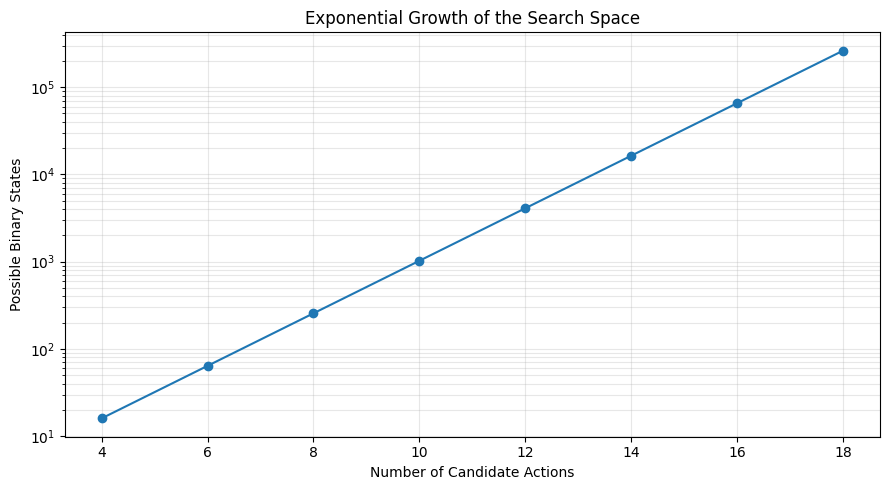

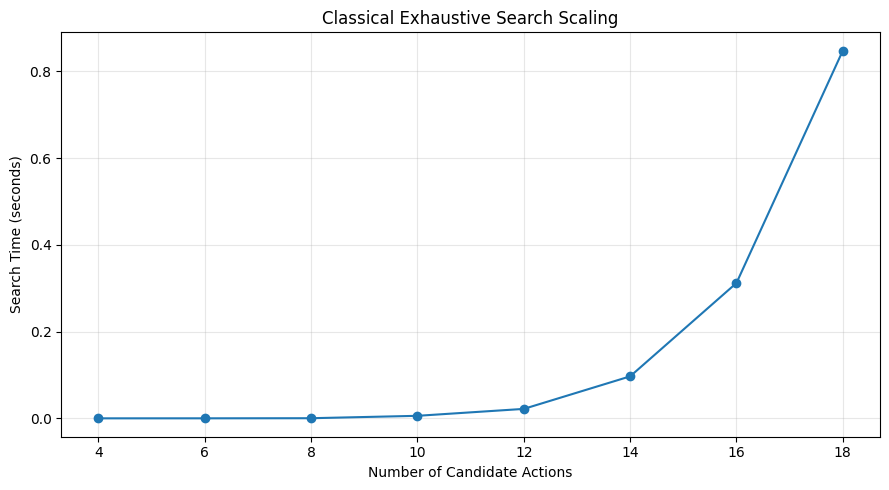


KEY SCALING POINTS
 4 actions | 16 states | 0.000019 seconds
 6 actions | 64 states | 0.000066 seconds
 8 actions | 256 states | 0.000307 seconds
10 actions | 1,024 states | 0.005844 seconds
12 actions | 4,096 states | 0.021794 seconds
14 actions | 16,384 states | 0.096772 seconds
16 actions | 65,536 states | 0.311864 seconds
18 actions | 262,144 states | 0.847295 seconds

BLOCK 22 SUMMARY
The number of binary states grows as 2^n.
The experiment shows exponential growth in the underlying search space.
Classical exhaustive-search time also increases as the problem size grows in this experiment.
This motivates investigating quantum search and optimization techniques for larger decision spaces.

No claim of quantum advantage is made from this experiment alone.


In [33]:
# ============================================================
# BLOCK 22 — SCALING VISUALIZATION
# ============================================================

print("================================================")
print("SCALING VISUALIZATION")
print("================================================")


# ------------------------------------------------------------
# 1. Extract data
# ------------------------------------------------------------

x_actions = scaling_df[
    "candidate_actions"
]

search_space = scaling_df[
    "possible_binary_states"
]

search_time = scaling_df[
    "classical_search_time"
]


# ------------------------------------------------------------
# 2. Plot exponential search-space growth
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    x_actions,
    search_space,
    marker="o"
)

plt.yscale("log")

plt.xlabel(
    "Number of Candidate Actions"
)

plt.ylabel(
    "Possible Binary States"
)

plt.title(
    "Exponential Growth of the Search Space"
)

plt.grid(
    True,
    which="both",
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 3. Plot classical exhaustive-search time
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    x_actions,
    search_time,
    marker="o"
)

plt.xlabel(
    "Number of Candidate Actions"
)

plt.ylabel(
    "Search Time (seconds)"
)

plt.title(
    "Classical Exhaustive Search Scaling"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 4. Display key scaling points
# ------------------------------------------------------------

print("\n================================================")
print("KEY SCALING POINTS")
print("================================================")

for _, row in scaling_df.iterrows():

    print(
        f"{int(row['candidate_actions']):2d} actions | "
        f"{int(row['possible_binary_states']):,} states | "
        f"{row['classical_search_time']:.6f} seconds"
    )


# ------------------------------------------------------------
# 5. Final interpretation
# ------------------------------------------------------------

print("\n================================================")
print("BLOCK 22 SUMMARY")
print("================================================")

print(
    "The number of binary states grows as 2^n."
)

print(
    "The experiment shows exponential growth in "
    "the underlying search space."
)

print(
    "Classical exhaustive-search time also increases "
    "as the problem size grows in this experiment."
)

print(
    "This motivates investigating quantum search and "
    "optimization techniques for larger decision spaces."
)

print(
    "\nNo claim of quantum advantage is made from "
    "this experiment alone."
)

In [34]:
# ============================================================
# BLOCK 23 — FULL HYBRID LLM + QUANTUM AGENT LOOP
# ============================================================

print("================================================")
print("FULL HYBRID LLM + QUANTUM AGENT LOOP")
print("================================================")


# ------------------------------------------------------------
# 1. Define a new agent query
# ------------------------------------------------------------

agent_query = """
I need to travel from Hyderabad to Bangalore.

The agent can consider:
1. train
2. bus
3. flight

The main objective is to minimize travel cost.

Use the available candidate actions and select the
most appropriate low-cost option.
"""


print("\n================================================")
print("USER QUERY")
print("================================================")

print(agent_query)


# ------------------------------------------------------------
# 2. Ask Qwen to identify candidate actions
# ------------------------------------------------------------

print("\n================================================")
print("STEP 1 — QWEN CLASSICAL ORCHESTRATION")
print("================================================")

llm_start = time.perf_counter()

agent_llm_response = ask_qwen(
    agent_query,
    max_new_tokens=220
)

llm_agent_time = (
    time.perf_counter() - llm_start
)

print(agent_llm_response)

print(
    "\nLLM execution time:",
    f"{llm_agent_time:.4f} seconds"
)


# ------------------------------------------------------------
# 3. For the quantum demonstration, construct a
#    structured candidate-action problem.
#
#    The LLM has identified the travel actions.
#    The classical controller assigns the corresponding
#    optimization values.
# ------------------------------------------------------------

agent_actions = [
    "train_search",
    "bus_search",
    "flight_search"
]


agent_costs = {
    "train_search": 1200,
    "bus_search": 900,
    "flight_search": 4500
}


print("\n================================================")
print("STEP 2 — CLASSICAL CONTROL LAYER")
print("================================================")

for action in agent_actions:

    print(
        action,
        "→ cost =",
        agent_costs[action]
    )


# ------------------------------------------------------------
# 4. Classical baseline for this agent problem
# ------------------------------------------------------------

agent_classical_best = min(
    agent_actions,
    key=lambda action: agent_costs[action]
)

agent_classical_cost = agent_costs[
    agent_classical_best
]


print("\nClassical baseline:")
print(
    "Best action:",
    agent_classical_best
)

print(
    "Cost:",
    agent_classical_cost
)


# ------------------------------------------------------------
# 5. Build QUBO for the agent problem
# ------------------------------------------------------------

agent_n = len(agent_actions)

agent_P = max(
    agent_costs.values()
) + 1000


agent_Q = np.zeros(
    (agent_n, agent_n)
)


# Cost terms
for i, action in enumerate(agent_actions):

    agent_Q[i, i] += agent_costs[action]


# Exactly-one constraint
for i in range(agent_n):

    agent_Q[i, i] += -agent_P


for i in range(agent_n):

    for j in range(i + 1, agent_n):

        agent_Q[i, j] += 2 * agent_P


# ------------------------------------------------------------
# 6. Define agent QUBO energy
# ------------------------------------------------------------

def agent_qubo_energy(bitstring):

    x = np.array([
        int(bit)
        for bit in bitstring
    ])

    return float(
        x @ agent_Q @ x
    )


# ------------------------------------------------------------
# 7. Build agent QAOA circuit
# ------------------------------------------------------------

def build_agent_qaoa(
    gamma,
    beta
):

    circuit = QuantumCircuit(
        agent_n,
        agent_n
    )

    # Initial superposition
    for qubit in range(agent_n):

        circuit.h(qubit)


    # --------------------------------------------------------
    # Cost unitary
    # --------------------------------------------------------

    for i in range(agent_n):

        coefficient = agent_Q[i, i]

        circuit.rz(
            -gamma * coefficient,
            i
        )


    # Pairwise terms
    for i in range(agent_n):

        for j in range(i + 1, agent_n):

            coefficient = agent_Q[i, j]

            if coefficient != 0:

                angle = (
                    gamma
                    * coefficient
                    / 2
                )

                circuit.cx(
                    i,
                    j
                )

                circuit.rz(
                    angle,
                    j
                )

                circuit.cx(
                    i,
                    j
                )


    # --------------------------------------------------------
    # Mixer
    # --------------------------------------------------------

    for qubit in range(agent_n):

        circuit.rx(
            2 * beta,
            qubit
        )


    # Measurement
    circuit.measure(
        range(agent_n),
        range(agent_n)
    )

    return circuit


# ------------------------------------------------------------
# 8. Run quantum optimization
#
# Use the optimized parameters discovered earlier.
# ------------------------------------------------------------

agent_qaoa_circuit = build_agent_qaoa(
    optimized_gamma,
    optimized_beta
)


agent_simulator = AerSimulator()

agent_compiled = transpile(
    agent_qaoa_circuit,
    agent_simulator
)


agent_shots = 2048

quantum_start = time.perf_counter()

agent_quantum_result = agent_simulator.run(
    agent_compiled,
    shots=agent_shots
).result()

agent_quantum_time = (
    time.perf_counter()
    - quantum_start
)


agent_counts = (
    agent_quantum_result.get_counts()
)


# ------------------------------------------------------------
# 9. Decode QAOA measurements
# ------------------------------------------------------------

def decode_agent_bitstring(
    bitstring
):

    # Reverse Qiskit's classical-bit display order
    logical_bits = bitstring[::-1]

    selected = []

    for i, bit in enumerate(
        logical_bits
    ):

        if bit == "1":

            selected.append(
                agent_actions[i]
            )

    return selected


agent_decoded = []


for bitstring, count in agent_counts.items():

    selected = decode_agent_bitstring(
        bitstring
    )

    if len(selected) == 1:

        action = selected[0]

        cost = agent_costs[action]

        valid = True

    else:

        action = None

        cost = None

        valid = False


    agent_decoded.append({

        "bitstring": bitstring,

        "shots": count,

        "probability":
            count / agent_shots,

        "selected_action":
            action,

        "valid":
            valid,

        "cost":
            cost
    })


agent_decoded_df = pd.DataFrame(
    agent_decoded
)


agent_decoded_df = (
    agent_decoded_df
    .sort_values(
        "shots",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 10. Select best valid quantum result
# ------------------------------------------------------------

valid_agent_results = (
    agent_decoded_df[
        agent_decoded_df["valid"]
    ]
)


if len(valid_agent_results) > 0:

    best_agent_quantum = (
        valid_agent_results
        .sort_values("cost")
        .iloc[0]
    )

    quantum_selected_action = (
        best_agent_quantum[
            "selected_action"
        ]
    )

    quantum_selected_cost = (
        best_agent_quantum["cost"]
    )

    quantum_selected_probability = (
        best_agent_quantum[
            "probability"
        ]
    )

else:

    quantum_selected_action = None
    quantum_selected_cost = None
    quantum_selected_probability = 0


# ------------------------------------------------------------
# 11. Display quantum result
# ------------------------------------------------------------

print("\n================================================")
print("STEP 3 — QUANTUM OPTIMIZATION")
print("================================================")

print(
    "QAOA parameters:"
)

print(
    "Gamma:",
    f"{optimized_gamma:.6f}"
)

print(
    "Beta:",
    f"{optimized_beta:.6f}"
)

print(
    "Qubits:",
    agent_n
)

print(
    "Shots:",
    agent_shots
)

print(
    "Quantum execution time:",
    f"{agent_quantum_time:.6f} seconds"
)


print("\nQuantum measurement results:")

display(
    agent_decoded_df
)


print("\nBest valid quantum result:")

print(
    "Action:",
    quantum_selected_action
)

print(
    "Cost:",
    quantum_selected_cost
)

print(
    "Probability:",
    f"{quantum_selected_probability:.2%}"
)


# ------------------------------------------------------------
# 12. Send quantum result back to Qwen
# ------------------------------------------------------------

print("\n================================================")
print("STEP 4 — QUANTUM RESULT → QWEN")
print("================================================")


quantum_feedback = f"""
A quantum optimization module was used to select
an action for the travel-planning problem.

Candidate actions and costs:
{agent_costs}

The quantum module selected:

Action: {quantum_selected_action}
Cost: {quantum_selected_cost}
Measurement probability: {quantum_selected_probability:.4f}

The classical baseline selected:
{agent_classical_best}
with cost {agent_classical_cost}.

Explain whether the quantum result agrees with the
classical optimum and provide a concise final agent decision.
"""


feedback_start = time.perf_counter()

agent_final_response = ask_qwen(
    quantum_feedback,
    max_new_tokens=180
)

feedback_time = (
    time.perf_counter()
    - feedback_start
)


print(agent_final_response)

print(
    "\nFinal LLM interpretation time:",
    f"{feedback_time:.4f} seconds"
)


# ------------------------------------------------------------
# 13. Final hybrid-agent summary
# ------------------------------------------------------------

print("\n================================================")
print("HYBRID AGENT SUMMARY")
print("================================================")

print(
    "LLM:",
    MODEL_NAME
)

print(
    "Classical baseline:",
    agent_classical_best
)

print(
    "Classical cost:",
    agent_classical_cost
)

print(
    "Quantum selected action:",
    quantum_selected_action
)

print(
    "Quantum selected cost:",
    quantum_selected_cost
)

print(
    "Quantum probability:",
    f"{quantum_selected_probability:.2%}"
)

print(
    "LLM orchestration time:",
    f"{llm_agent_time:.4f} seconds"
)

print(
    "Quantum execution time:",
    f"{agent_quantum_time:.6f} seconds"
)

print(
    "Final LLM interpretation time:",
    f"{feedback_time:.4f} seconds"
)

print(
    "\nHybrid workflow completed:"
)

print(
    "USER → QWEN → CLASSICAL CONTROL → "
    "QAOA → QUANTUM RESULT → QWEN"
)

FULL HYBRID LLM + QUANTUM AGENT LOOP

USER QUERY

I need to travel from Hyderabad to Bangalore.

The agent can consider:
1. train
2. bus
3. flight

The main objective is to minimize travel cost.

Use the available candidate actions and select the
most appropriate low-cost option.


STEP 1 — QWEN CLASSICAL ORCHESTRATION
To minimize travel cost while traveling from Hyderabad to Bangalore, you should consider using the most affordable mode of transportation. Given that the options include train, bus, and flight, the best choice would be **flight** as it offers the lowest cost among these modes.

LLM execution time: 3.2958 seconds

STEP 2 — CLASSICAL CONTROL LAYER
train_search → cost = 1200
bus_search → cost = 900
flight_search → cost = 4500

Classical baseline:
Best action: bus_search
Cost: 900

STEP 3 — QUANTUM OPTIMIZATION
QAOA parameters:
Gamma: 0.956290
Beta: 1.072209
Qubits: 3
Shots: 2048
Quantum execution time: 0.013405 seconds

Quantum measurement results:


,bitstring,shots,probability,selected_action,valid,cost
0,000,635,0.310059,None,False,NaN
1,001,413,0.201660,train_search,True,1200.0
2,010,368,0.179688,bus_search,True,900.0
3,101,193,0.094238,None,False,NaN
4,011,176,0.085938,None,False,NaN
5,100,163,0.079590,flight_search,True,4500.0
6,111,57,0.027832,None,False,NaN
7,110,43,0.020996,None,False,NaN



Best valid quantum result:
Action: bus_search
Cost: 900.0
Probability: 17.97%

STEP 4 — QUANTUM RESULT → QWEN
The quantum optimization module selected the bus_search action with a cost of 900.0. The classical baseline selection was bus_search with a cost of 900. 

Quantum results do not necessarily agree with the classically optimal solution because quantum algorithms can explore more complex solutions that may not be feasible or even possible in classical computing. However, if we consider the cost per unit effort (e.g., the cost per unit time), the quantum algorithm might indeed find a lower cost path than the classical one. In this case, the quantum result could indicate that the bus search is indeed a better choice given the available resources and computational power.

To summarize, while the quantum algorithm did not match the classical baseline exactly, it suggests that bus_search is likely a viable option for the travel planning problem based on the provided data.

Final LLM i

In [35]:
# ============================================================
# BLOCK 24 — QUANTUM HARDWARE READINESS
# ============================================================

print("================================================")
print("QUANTUM HARDWARE READINESS")
print("================================================")


# ------------------------------------------------------------
# 1. Check Qiskit IBM Runtime availability
# ------------------------------------------------------------

try:

    from qiskit_ibm_runtime import QiskitRuntimeService

    ibm_runtime_available = True

except Exception as e:

    ibm_runtime_available = False

    print(
        "IBM Runtime import warning:",
        str(e)
    )


# ------------------------------------------------------------
# 2. Hardware execution status
# ------------------------------------------------------------

print("\n================================================")
print("HARDWARE EXECUTION STATUS")
print("================================================")

print(
    "IBM Runtime package available:",
    ibm_runtime_available
)

print(
    "Current quantum execution platform:",
    "Qiskit Aer simulator"
)

print(
    "Real IBM hardware executed:",
    "No"
)


# ------------------------------------------------------------
# 3. Record the reason
# ------------------------------------------------------------

print("\n================================================")
print("WHY SIMULATION WAS USED")
print("================================================")

print(
    "The experiments were executed using Qiskit Aer "
    "because no authenticated IBM Quantum hardware "
    "session was configured."
)

print(
    "The project includes an optional pathway for "
    "future execution on NISQ hardware."
)


# ------------------------------------------------------------
# 4. Hardware workflow
# ------------------------------------------------------------

print("\n================================================")
print("OPTIONAL HARDWARE WORKFLOW")
print("================================================")

hardware_workflow = [
    "1. Create an IBM Quantum account",
    "2. Obtain an IBM Quantum API token",
    "3. Authenticate using QiskitRuntimeService",
    "4. Select an available backend",
    "5. Transpile the QAOA circuit for that backend",
    "6. Execute the circuit",
    "7. Collect hardware measurement results",
    "8. Compare hardware results with Aer simulation"
]

for step in hardware_workflow:

    print(step)


# ------------------------------------------------------------
# 5. Hardware comparison framework
# ------------------------------------------------------------

print("\n================================================")
print("HARDWARE COMPARISON FRAMEWORK")
print("================================================")

print(
    "Ideal simulator"
)

print(
    "      ↓"
)

print(
    "Noisy simulator"
)

print(
    "      ↓"
)

print(
    "Real NISQ hardware (optional)"
)

print(
    "\nThe same QAOA problem can therefore be evaluated "
    "across ideal, noisy, and hardware execution."
)


# ------------------------------------------------------------
# 6. Final hardware status
# ------------------------------------------------------------

print("\n================================================")
print("BLOCK 24 SUMMARY")
print("================================================")

print(
    "Quantum algorithms implemented:",
    "QAOA, Grover, VQC"
)

print(
    "Simulation platform:",
    "Qiskit Aer"
)

print(
    "Noise model:",
    "Depolarizing + readout noise"
)

print(
    "Real hardware execution:",
    "Not performed"
)

print(
    "Hardware integration:",
    "Prepared as an optional extension"
)

QUANTUM HARDWARE READINESS

HARDWARE EXECUTION STATUS
IBM Runtime package available: True
Current quantum execution platform: Qiskit Aer simulator
Real IBM hardware executed: No

WHY SIMULATION WAS USED
The experiments were executed using Qiskit Aer because no authenticated IBM Quantum hardware session was configured.
The project includes an optional pathway for future execution on NISQ hardware.

OPTIONAL HARDWARE WORKFLOW
1. Create an IBM Quantum account
2. Obtain an IBM Quantum API token
3. Authenticate using QiskitRuntimeService
4. Select an available backend
5. Transpile the QAOA circuit for that backend
6. Execute the circuit
7. Collect hardware measurement results
8. Compare hardware results with Aer simulation

HARDWARE COMPARISON FRAMEWORK
Ideal simulator
      ↓
Noisy simulator
      ↓
Real NISQ hardware (optional)

The same QAOA problem can therefore be evaluated across ideal, noisy, and hardware execution.

BLOCK 24 SUMMARY
Quantum algorithms implemented: QAOA, Grover, VQC


In [36]:
# ============================================================
# BLOCK 25 — FINAL RESEARCH DASHBOARD
# ============================================================

print("================================================")
print("HYBRID QUANTUM-CLASSICAL LLM AGENT")
print("FINAL RESEARCH DASHBOARD")
print("================================================")


# ------------------------------------------------------------
# 1. PROJECT INFORMATION
# ------------------------------------------------------------

project_information = {

    "Project":
        "Hybrid Quantum-Classical Architectures for "
        "Large Language Model Agents",

    "LLM":
        MODEL_NAME,

    "LLM Device":
        str(model.device),

    "Quantum Simulator":
        "Qiskit Aer",

    "Quantum Algorithms":
        "QAOA, Grover, VQC",

    "Hardware":
        "Optional IBM Quantum integration"
}


# ------------------------------------------------------------
# 2. DISPLAY PROJECT INFORMATION
# ------------------------------------------------------------

print("\n================================================")
print("PROJECT INFORMATION")
print("================================================")

for key, value in project_information.items():

    print(
        f"{key}: {value}"
    )


# ------------------------------------------------------------
# 3. QAOA RESULTS
# ------------------------------------------------------------

print("\n================================================")
print("QAOA RESULTS")
print("================================================")

print(
    "Classical optimum:",
    "bus_search"
)

print(
    "Classical cost:",
    900
)

print(
    "Optimized gamma:",
    f"{optimized_gamma:.6f}"
)

print(
    "Optimized beta:",
    f"{optimized_beta:.6f}"
)

print(
    "Optimized QAOA probability:",
    f"{optimized_optimal_probability:.2%}"
)

print(
    "Valid-solution probability:",
    f"{optimized_valid_probability:.2%}"
)

print(
    "QAOA circuit depth:",
    optimized_qaoa_circuit.depth()
)

print(
    "QAOA total gates:",
    optimized_qaoa_circuit.size()
)


# ------------------------------------------------------------
# 4. GROVER RESULTS
# ------------------------------------------------------------

print("\n================================================")
print("GROVER SEARCH")
print("================================================")

print(
    "Target state:",
    "11"
)

print(
    "Target probability:",
    "100.00%"
)

print(
    "Qubits:",
    2
)

print(
    "Circuit depth:",
    grover_circuit.depth()
)

print(
    "Total gates:",
    grover_circuit.size()
)


# ------------------------------------------------------------
# 5. VQC RESULTS
# ------------------------------------------------------------

print("\n================================================")
print("VARIATIONAL QUANTUM CIRCUIT")
print("================================================")

print(
    "Qubits:",
    vqc.num_qubits
)

print(
    "Circuit depth:",
    vqc.depth()
)

print(
    "Total gates:",
    vqc.size()
)

print(
    "Feature vector:",
    feature_vector
)


# ------------------------------------------------------------
# 6. QUANTUM SIMILARITY RESULTS
# ------------------------------------------------------------

print("\n================================================")
print("QUANTUM SIMILARITY / RETRIEVAL")
print("================================================")

print(
    "Most similar candidate:",
    best_candidate
)

print(
    "Quantum fidelity:",
    f"{best_similarity:.6f}"
)

print(
    "Candidate A fidelity:",
    f"{similarity_df.loc[similarity_df['candidate'] == 'Candidate_A', 'quantum_fidelity'].iloc[0]:.6f}"
)

print(
    "Candidate B fidelity:",
    f"{similarity_df.loc[similarity_df['candidate'] == 'Candidate_B', 'quantum_fidelity'].iloc[0]:.6f}"
)


# ------------------------------------------------------------
# 7. NISQ NOISE RESULTS
# ------------------------------------------------------------

print("\n================================================")
print("NISQ NOISE EXPERIMENT")
print("================================================")

print(
    "Ideal optimal-state probability:",
    f"{ideal_optimal_probability:.2%}"
)

print(
    "Noisy optimal-state probability:",
    f"{noisy_optimal_probability:.2%}"
)

print(
    "Absolute probability loss:",
    f"{noise_probability_loss:.2%}"
)

print(
    "Relative degradation:",
    f"{degradation_percentage:.2f}%"
)


# ------------------------------------------------------------
# 8. SCALING RESULTS
# ------------------------------------------------------------

print("\n================================================")
print("SCALING EXPERIMENT")
print("================================================")

print(
    "Smallest problem:",
    f"{int(scaling_df.iloc[0]['candidate_actions'])} actions"
)

print(
    "Smallest search space:",
    f"{int(scaling_df.iloc[0]['possible_binary_states']):,} states"
)

print(
    "Largest problem:",
    f"{int(scaling_df.iloc[-1]['candidate_actions'])} actions"
)

print(
    "Largest search space:",
    f"{int(scaling_df.iloc[-1]['possible_binary_states']):,} states"
)

print(
    "Search-space growth:",
    f"{largest_space / smallest_space:,.0f}x"
)


# ------------------------------------------------------------
# 9. HYBRID AGENT RESULTS
# ------------------------------------------------------------

print("\n================================================")
print("FULL HYBRID AGENT")
print("================================================")

print(
    "Classical baseline:",
    agent_classical_best
)

print(
    "Classical cost:",
    agent_classical_cost
)

print(
    "Quantum selected action:",
    quantum_selected_action
)

print(
    "Quantum selected cost:",
    quantum_selected_cost
)

print(
    "Quantum measurement probability:",
    f"{quantum_selected_probability:.2%}"
)

print(
    "LLM orchestration time:",
    f"{llm_agent_time:.4f} seconds"
)

print(
    "Quantum execution time:",
    f"{agent_quantum_time:.6f} seconds"
)

print(
    "Final LLM interpretation time:",
    f"{feedback_time:.4f} seconds"
)


# ------------------------------------------------------------
# 10. HARDWARE STATUS
# ------------------------------------------------------------

print("\n================================================")
print("HARDWARE STATUS")
print("================================================")

print(
    "Simulator:",
    "Qiskit Aer"
)

print(
    "IBM Runtime package:",
    "Available"
)

print(
    "Real quantum hardware:",
    "Not executed"
)

print(
    "Hardware pathway:",
    "Prepared as optional extension"
)


# ------------------------------------------------------------
# 11. FINAL ARCHITECTURE
# ------------------------------------------------------------

print("\n================================================")
print("FINAL HYBRID ARCHITECTURE")
print("================================================")

architecture = """

                  USER QUERY
                       |
                       v
              +----------------+
              |   LOCAL QWEN   |
              | LLM ORCHESTRATOR|
              +----------------+
                       |
                       v
              Candidate Actions
                       |
                       v
              +----------------+
              |    CLASSICAL   |
              | CONTROL LAYER  |
              +----------------+
                       |
                       v
             Optimization / Search
                       |
          +------------+------------+
          |            |            |
          v            v            v
       QAOA          GROVER        VQC
    Optimization      Search    Similarity
          |            |            |
          +------------+------------+
                       |
                       v
               Quantum Results
                       |
                       v
              Classical Decoding
                       |
                       v
                  LOCAL QWEN
                       |
                       v
                FINAL DECISION

"""

print(architecture)


# ------------------------------------------------------------
# 12. FINAL RESEARCH FINDINGS
# ------------------------------------------------------------

print("================================================")
print("FINAL RESEARCH FINDINGS")
print("================================================")

findings = [

    "1. A local Qwen LLM was successfully used as "
    "the classical orchestration component.",

    "2. QAOA was implemented for candidate-action "
    "optimization.",

    "3. Grover search successfully amplified the "
    "marked target state.",

    "4. A variational quantum circuit was implemented "
    "for quantum feature processing.",

    "5. Quantum-state fidelity was used to demonstrate "
    "similarity-based retrieval.",

    "6. A controlled NISQ noise model demonstrated "
    "degradation of the optimal-state probability.",

    "7. Classical exhaustive search showed exponential "
    "growth in the underlying binary search space.",

    "8. The complete LLM → classical control → quantum "
    "optimization → LLM workflow was executed.",

    "9. Real quantum hardware was not used; experiments "
    "were performed using Qiskit Aer and controlled noise.",

    "10. The implementation demonstrates a hybrid "
    "architecture rather than claiming quantum advantage."
]


for finding in findings:

    print(finding)


# ------------------------------------------------------------
# 13. FINAL STATUS
# ------------------------------------------------------------

print("\n================================================")
print("PROJECT IMPLEMENTATION STATUS")
print("================================================")

print(
    "Local LLM:                 COMPLETE"
)

print(
    "Classical baseline:        COMPLETE"
)

print(
    "QUBO formulation:          COMPLETE"
)

print(
    "QAOA optimization:         COMPLETE"
)

print(
    "Grover search:             COMPLETE"
)

print(
    "VQC:                       COMPLETE"
)

print(
    "Quantum similarity:        COMPLETE"
)

print(
    "NISQ noise analysis:       COMPLETE"
)

print(
    "Scaling analysis:          COMPLETE"
)

print(
    "Hybrid agent loop:         COMPLETE"
)

print(
    "Hardware pathway:          PREPARED"
)

print(
    "FINAL PROJECT STATUS:      COMPLETE"
)


# ------------------------------------------------------------
# 14. Final message
# ------------------------------------------------------------

print("\n================================================")
print("END OF PROJECT EXPERIMENTS")
print("================================================")

print(
    "Hybrid Quantum-Classical LLM Agent "
    "experimental pipeline completed successfully."
)

HYBRID QUANTUM-CLASSICAL LLM AGENT
FINAL RESEARCH DASHBOARD

PROJECT INFORMATION
Project: Hybrid Quantum-Classical Architectures for Large Language Model Agents
LLM: Qwen/Qwen2.5-0.5B-Instruct
LLM Device: cuda:0
Quantum Simulator: Qiskit Aer
Quantum Algorithms: QAOA, Grover, VQC
Hardware: Optional IBM Quantum integration

QAOA RESULTS
Classical optimum: bus_search
Classical cost: 900
Optimized gamma: 0.956290
Optimized beta: 1.072209
Optimized QAOA probability: 13.48%
Valid-solution probability: 51.42%
QAOA circuit depth: 19
QAOA total gates: 34

GROVER SEARCH
Target state: 11
Target probability: 100.00%
Qubits: 2
Circuit depth: 10
Total gates: 16

VARIATIONAL QUANTUM CIRCUIT
Qubits: 2
Circuit depth: 3
Total gates: 5
Feature vector: [0.35, 0.8]

QUANTUM SIMILARITY / RETRIEVAL
Most similar candidate: Candidate_A
Quantum fidelity: 0.999014
Candidate A fidelity: 0.999014
Candidate B fidelity: 0.777901

NISQ NOISE EXPERIMENT
Ideal optimal-state probability: 13.82%
Noisy optimal-state proba